# RunWay — 마라톤 코스 최적화 Step by Step (PuLP 수리최적화 버전)

> **버스 승객 피해는 최소로, 러너의 '롯데타워 순간'은 그대로.**
> 대회 기획자의 요청을 LLM 에이전트가 **제약(JSON)** 으로 바꾸면, 이 노트북의 **MILP 솔버(PuLP)** 가 서울시 버스 승하차 공공데이터로
> 시민 피해가 가장 적은 42.195km 코스를 계산한다. **LLM은 의미를, 솔버는 숫자를** 맡는다 — 이 노트북은 그중 '숫자' 쪽 엔진이다.

| | 내용 |
|---|---|
| **AS-IS** | 2026 JTBC 서울마라톤 풀코스(공식 경유지를 도로망 위에 옮긴 코스) |
| **TO-BE** | 이 노트북의 MILP가 계산한 코스 |
| **목적** | 통제 시간대 버스 승객 피해 + 영향(우회) 노선 수 최소화 |
| **지켜야 할 것** | 공인 거리 42.195km, 출발(광화문)·도착(올림픽공원) 고정, **대회 정체성**(30km 이후 롯데월드타워 조망 ≥ 하한), 금지 구간(병원 앞), 차로 수, 러너가 외우기 쉬운 단순한 코스 |

### 프로젝트 소개서와의 연결
| 소개서의 약속 | 이 노트북에서 |
|---|---|
| 정체성을 JSON 스키마 `{L_k, a_k, b_k, w_k, 금지 구간}`로 받는다 | `P['IDENTITY']`, `P['FORBID']` — 에이전트가 채울 자리 (Step 0 파라미터) |
| MILP(PuLP)로 우회 노선 + 통제 시간대 승차 인원 최소화 | Step 5 수식 → Step 7 실행 |
| 정체성 점수: 30km 이후 롯데타워 조망 거리 ≥ 하한 | 제약식 (7) |
| 2026 실제 코스 대비 KPI 비교 | Step 6·9 |
| 정체성 하한별 **파레토 곡선** ("조망 1km 줄이면 승객 ○명 감소") | Step 8 |
| 출발 시각 시나리오 비교 | Step 10 |
| 숫자는 솔버만 산출 → 설명문은 결과 변수만 인용 | Step 11 저장 파일 |

### JTBC 서울마라톤 사무국 재설계 방침(2026-11)과의 연결
| 사무국이 밝힌 방향 | 모델에서 다루는 방법 |
|---|---|
| 코스와 **일정**을 원점에서 재설계, 교통·지역 영향 최소화 | 목적식 = 승객 피해 + 영향 노선 수, 출발 시각 시나리오 (Step 10) |
| 관계기관(서울시·경찰) 협의 | 통제 시간 모델을 경찰 발표 통제 시각에 맞춰 보정, 구간별 통제 시각표 출력 |
| 코스를 접수 전 확정·공개 | 같은 데이터·파라미터면 같은 해(최적해)가 나오는 재현 가능한 계산, GeoJSON 저장 |
| 현장 운영 인력·민원 대응 | 통제 필요 교차로 수·통제 부담(km×시간)을 KPI로, 꺾임·되돌아오기 벌점으로 단순한 코스 |

**순서**: ① 데이터 → ② 도로 그래프 → ③ 통제시간·승객피해 → ④ 정체성·안전·단순성 → ⑤ MILP 수식과 PuLP 코드 → ⑥ AS-IS 평가 → ⑦ TO-BE 최적화 → ⑧ 정체성 파레토(최종 TO-BE 확정) → ⑨ AS-IS vs TO-BE 비교 → ⑩ 출발 시각 시나리오 → ⑪ 결과 저장

**실행 환경**: Python 3.10+, **`pip install "pulp[highs]"`** (PuLP + HiGHS 솔버, 권장). 그 밖에 `numpy pandas networkx scipy matplotlib openpyxl`.
- PuLP 3.x·4.x 모두 동작한다. PuLP 4.x는 CBC를 내장하지 않으므로 CBC를 쓰려면 `pip install "pulp[cbc]"`. HiGHS와 CBC가 둘 다 있으면 HiGHS를 쓴다.
`data/` 폴더에 아래 5개 파일이 있어야 한다.

| 파일 | 출처 | 내용 |
|---|---|---|
| `bus_stop_agg_202610.csv` | 서울 열린데이터광장 OA-12913 (버스노선별 정류장별 시간대별 승하차) 2026-10 | 정류장(ARS)별 06~14시 시간대 승차 합계(월), 경유 노선 |
| `bus_stop_daytype_202610.csv` | 서울 열린데이터광장 OA-12912 (버스노선별 정류장별 승하차, 일별) 2026-10 | 정류장(ARS)별 월 합계·토요일 합계·일요일 합계 승차 |
| `bus_stop_xy_20260902.xlsx` | 서울 열린데이터광장 OA-15067 (버스정류소 위치정보) | ARS_ID, 좌표(WGS84) |
| `osm_roads.json` | OpenStreetMap (Overpass API) | 서울 간선·주간선·보조간선 도로 |
| `tunnel_way_ids.txt` | OpenStreetMap (`tunnel=*`) | 터널 구간 way id (코스에서 제외) |

## Step 0. 라이브러리와 파라미터
아래 `P`가 **에이전트가 채우는 제약 카드**다. 특히 `IDENTITY`(대회 정체성)와 `FORBID`(금지 구간)는 소개서의 JSON 스키마 `{L_k, a_k, b_k, w_k, 금지 구간}` 그대로다.

In [1]:
import json, math, os, re, time
from pathlib import Path
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt
from matplotlib import font_manager
from scipy.spatial import cKDTree
try:
    import pulp
except ImportError:
    raise ImportError('PuLP가 없습니다. 먼저 `pip install "pulp[highs]"` (Colab: `!pip install "pulp[highs]"`)를 실행하세요.')

DATA, OUT = Path('data'), Path('out'); OUT.mkdir(exist_ok=True)

# 한글 폰트(있는 것 사용)
for f in font_manager.findSystemFonts():
    if any(k in f for k in ('NotoSansCJK', 'NanumGothic', 'malgun', 'AppleGothic', 'AppleSDGothic')):
        font_manager.fontManager.addfont(f)
        plt.rcParams['font.family'] = font_manager.FontProperties(fname=f).get_name(); break
plt.rcParams['axes.unicode_minus'] = False

# ───────── 모델 파라미터 = 제약 카드 (챗봇에서는 LLM 에이전트가 대화로 이 값을 바꾼다) ─────────
P = dict(
    # 일정·통제 시간
    T0=8.0,                  # 출발 시각 08:00 (2026 대회 실제 출발 시각)
    V_LEAD=20.0,             # 선두 속도 km/h (통제 시작 기준)
    V_SWEEP=42.195 / 5.0,    # 후미(회수차) 속도 km/h = 5시간 컷오프 (통제 해제 기준)
    PRE=0.25, POST=0.5,      # 통제 시작 전·해제 후 여유 (시간) — 경찰 발표 통제 시각에 맞춰 보정
    STAGE=(600.0, 4.0, 10.0),            # 집결·출발지: 출발점부터 600m는 04:00~10:00 통제
    # 공인 코스 조건
    LMIN=42195.0, LMAX=42600.0,           # 코스 길이 허용 범위 (m) — 42.195km 이상, 계측 여유 405m
    START=(37.5716, 126.9768),            # 광화문광장
    FINISH=(37.5207, 127.1214),           # 올림픽공원
    # 대회 정체성 (소개서 스키마: L_k 하한(m), [a_k, b_k] 적용 거리 구간(m), w_k 가중치)
    IDENTITY=[dict(name='롯데월드타워', type='view', coord=(37.5126, 127.1025), angle=30, dist=4000,
                   L=2000.0, a=30000.0, b=42600.0, w=0.0)],
    # 금지 구간 (반경 r m 안의 도로 진입 금지)
    FORBID=[dict(name='건국대병원 앞(응급 동선)', coord=(37.5404, 127.0718), r=150)],
    MIN_LANES=1.0,           # 한 방향 평균 차로 수가 이보다 적다고 OSM에 표시된 도로(1차로 양방향 골목 등)는 제외 (표시 없으면 허용)
    # 목적식 가중치 (단위: '막히는 승객 1명' = 1점)
    ALPHA=60.0,              # 영향(우회) 버스 노선 1개
    TURN=(1000.0, 2000.0, 5000.0),   # 방향 전환 1회: 45~100° / 100~150° / 150° 이상 — 단순한 코스 우선
    PEN_TWIN=3.0,            # 되돌아오기(달려온 길의 반대 차로) 1m
    PEN_NEAR=2.0, NEAR_R=(300.0, 800.0),   # 같은 동네 재방문 1m — 같은 방향 나란한 다른 길 300m / 반대 방향(갔다가 돌아오는 지그재그) 800m 이내
    EPS_LEN=0.02,            # 미세 거리비용 (보조간선은 ×1.6) — 같은 피해면 넓은 간선을 선호
    # 계산 설정
    STEP=10.0,               # 피해 비용표의 거리 간격 (m)
    JUNCTION_R=60.0,         # 이 거리(m) 안의 OSM 노드는 한 교차로로 묶는다
    BAND_KM=3.0,             # MILP 거리 구간대 폭 (km) — 위치별 피해를 이 단위로 근사
    LP_EPS=1e-3,             # LP 완화 해에서 이 값보다 큰 도로만 후보 회랑으로
    TIME_LIMIT=600, GAP=0.01,         # 솔버 시간 제한(초), 허용 최적성 gap(1%)
    DAYTYPE='weekend',       # 승차 수요 기준: 'weekend'(토·일 평균) | 'sunday'(일요일 평균) | 'all'(전체 일평균)
)

def hav(a, b): # 하버사인으로 거리 계산
    """두 (위도, 경도) 사이 거리(m)"""
    R = 6371000.0
    la1, lo1, la2, lo2 = map(math.radians, (a[0], a[1], b[0], b[1]))
    d = math.sin((la2 - la1) / 2) ** 2 + math.cos(la1) * math.cos(la2) * math.sin((lo2 - lo1) / 2) ** 2
    return 2 * R * math.asin(math.sqrt(d))

## Step 1. 데이터 불러오기
버스 승차 데이터는 **정류장 × 시간대** 단위다. 마라톤 통제는 06~14시 사이에만 일어나므로 그 시간대만 쓴다.
마라톤은 주말에 열리므로 **주말(토·일) 하루 평균**을 쓴다. 다만 시간대별 파일(OA-12913)은 월 합계만 있고 요일 구분이 없어서, 일별 파일(OA-12912)과 결합해 추정한다.

$$q^{주말}_{s,h} \;=\; \underbrace{M_{s,h}}_{\text{10월 시간대별 월 합계}} \times \underbrace{\frac{W_s / n_{주말}}{T_s}}_{\text{정류장별 주말 하루 비중}}$$

- $W_s$: 정류장 $s$의 10월 토·일 승차 합계(토 5일 + 일 4일 = 9일), $T_s$: 10월 전체 승차 합계 (모두 OA-12912 일별 실측)
- 즉 **수준(하루 몇 명)은 정류장별 주말 실측값**이고, **시간대 분포는 월 전체 분포**를 그대로 쓴다. 주말은 출근 피크가 약하므로 7~9시는 다소 과대, 낮 시간은 과소 추정될 수 있다.
- `P['DAYTYPE']`를 `'sunday'`로 바꾸면 일요일만(4일), `'all'`이면 기존 일평균으로 계산한다.

서울 전체 하루 승차: 전체 일평균 483만 | 토·일 평균 378만 | 일요일 평균 324만 명
승차 집계 정류장 12,350곳 | 좌표 정류소 11,236곳 | OSM 도로 way 6,201개, 노드 35,579개 | 터널 way 514개


,ars,std_id,name,h6,h7,h8,h9,h10,h11,h12,h13,h14,routes,f_weekend,f_sunday,f_all,f
0,01001,100000001,종로2가사거리(00089),630,1634,1883,2249,1876,2028,1920,1987,1722,N37|470|741,0.021977,0.016107,0.032258,0.021977
1,01002,100000002,창경궁.서울대학교병원(00015),6937,14215,18990,12497,9356,8977,8349,8791,9794,143|172|104|N31|8101|151|107|710|171|301|8111|...,0.025047,0.019375,0.032258,0.025047
2,01003,100000003,명륜3가.성대입구(00030),6815,11643,17407,13742,12198,12618,13638,14471,13383,100|8101|N31|151|301|140|150|102|104|160|172|2...,0.029795,0.024608,0.032258,0.029795


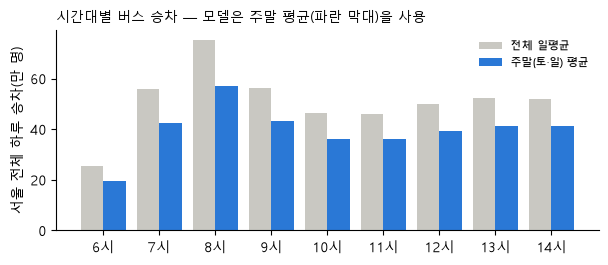

In [2]:
agg = pd.read_csv(DATA / 'bus_stop_agg_202610.csv', dtype={'ars': str}, encoding='utf-8-sig')
agg['ars'] = agg['ars'].str.zfill(5)
xy = pd.read_excel(DATA / 'bus_stop_xy_20260902.xlsx')
xy['ars'] = xy['ARS_ID'].astype(int).astype(str).str.zfill(5)
osm = json.load(open(DATA / 'osm_roads.json', encoding='utf-8'))
TUNNEL = set(int(x) for x in open(DATA / 'tunnel_way_ids.txt').read().strip().split(','))
HOURS = list(range(6, 15))

# 주말 하루 비중: 일별 파일에는 10/27 하루가 빠져 있어(30일치) 월 합계를 31/30로 보정
dt = pd.read_csv(DATA / 'bus_stop_daytype_202610.csv', dtype={'ars': str}, encoding='utf-8-sig')
dt['ars'] = dt['ars'].str.zfill(5); dt = dt.groupby('ars', as_index=False).sum()
T = dt['month_sum'] * 31 / 30
dt['f_weekend'] = (dt['sat_sum'] + dt['sun_sum']) / 9 / T
dt['f_sunday'] = dt['sun_sum'] / 4 / T
dt['f_all'] = 1 / 31
city = {k: float((dt['sat_sum'].sum() * (k != 'sunday') + dt['sun_sum'].sum()) / (9 if k == 'weekend' else 4) / T.sum()) for k in ('weekend', 'sunday')}
agg = agg.merge(dt[['ars', 'f_weekend', 'f_sunday', 'f_all']], on='ars', how='left')
agg['f'] = agg['f_' + P['DAYTYPE']].fillna(city.get(P['DAYTYPE'], 1 / 31))        # 일별 자료에 없는 정류장은 서울 평균 비중
print(f"서울 전체 하루 승차: 전체 일평균 {T.sum()/31/1e4:,.0f}만 | 토·일 평균 {(dt['sat_sum'].sum()+dt['sun_sum'].sum())/9/1e4:,.0f}만 | 일요일 평균 {dt['sun_sum'].sum()/4/1e4:,.0f}만 명")
print(f'승차 집계 정류장 {len(agg):,}곳 | 좌표 정류소 {len(xy):,}곳 | OSM 도로 way {len(osm["ways"]):,}개, 노드 {len(osm["nodes"]):,}개 | 터널 way {len(TUNNEL)}개')
display(agg.head(3))

fig, ax = plt.subplots(figsize=(7, 2.6))
x = np.arange(len(HOURS))
ax.bar(x - .2, [agg[f'h{h}'].sum() / 31 / 1e4 for h in HOURS], width=.4, color='#c9c8c2', label='전체 일평균')
ax.bar(x + .2, [(agg[f'h{h}'] * agg['f']).sum() / 1e4 for h in HOURS], width=.4, color='#2a78d6', label={'weekend': '주말(토·일) 평균', 'sunday': '일요일 평균', 'all': '전체 일평균'}[P['DAYTYPE']])
ax.set_xticks(x); ax.set_xticklabels([f'{h}시' for h in HOURS]); ax.legend(frameon=False, fontsize=8)
ax.set_ylabel('서울 전체 하루 승차(만 명)'); ax.set_title('시간대별 버스 승차 — 모델은 주말 평균(파란 막대)을 사용', loc='left', fontsize=10)
for s in ('top', 'right'): ax.spines[s].set_visible(False)
plt.show()

## Step 2. 도로 그래프 만들기
1. OSM에서 **마라톤이 달릴 수 있는 도로**만 남긴다: 간선(trunk)·주간선(primary)·보조간선(secondary). 도시고속도로·고가·긴 터널(400m 초과)은 제외.
2. 교차로가 아닌 중간 노드를 합쳐 **교차로–교차로 구간(segment)** 으로 축약한다 → 최적화 변수 수가 크게 줄어든다.
3. 왕복 분리 도로 때문에 한 교차로가 OSM 노드 여러 개로 쪼개져 있으므로 **60m 이내 노드를 한 교차로로 묶고** 다시 축약한다 → 모델이 작아지고, '방향 전환'이 실제 교차로 단위로 계산된다.
4. 버스 정류장을 **35m 이내의 가장 가까운 구간**에 붙인다. 그 구간이 통제되면 그 정류장 승객이 피해를 본다.

In [3]:
EXCLUDE = ['강변북로', '올림픽대로', '동부간선', '내부순환', '북부간선', '서부간선', '분당수서', '강남순환', '고가', '터널']
KEEP = {'trunk', 'primary', 'secondary'}
allnodes = {int(k): tuple(v) for k, v in osm['nodes'].items()}

# 2-1) 원본 그래프
G = nx.Graph()
for w in osm['ways']:
    if w['hw'] not in KEEP or any(x in w['name'] for x in EXCLUDE):
        continue
    ns = [n for n in w['nodes'] if n in allnodes]
    if w['id'] in TUNNEL and sum(hav(allnodes[a], allnodes[b]) for a, b in zip(ns[:-1], ns[1:])) > 400:
        continue                                   # 긴 터널(남산 1·3호 등)만 제외, 짧은 지하차도는 마라톤이 실제로 지나므로 유지
    ln = int(w['lanes']) if str(w['lanes']).isdigit() else None
    lanes = None if ln is None else (ln if w['oneway'] == 'yes' else ln / 2)   # 한 방향 차로 수 (OSM 표시가 없으면 None)
    for a, b in zip(ns[:-1], ns[1:]):
        if a != b and not G.has_edge(a, b):
            G.add_edge(a, b, length=hav(allnodes[a], allnodes[b]), name=w['name'], hw=w['hw'], lanes=lanes)
G = G.subgraph(max(nx.connected_components(G), key=len)).copy()

# 2-2) 차수 2 노드 축약 → 구간
keep = {n for n in G.nodes if G.degree(n) != 2}
segs, seen = [], set()
for u in keep:
    for v in G.neighbors(u):
        if (u, v) in seen:
            continue
        path, prev, cur = [u, v], u, v
        while cur not in keep:
            nxt = [x for x in G.neighbors(cur) if x != prev][0]
            path.append(nxt); prev, cur = cur, nxt
        ed = list(zip(path[:-1], path[1:]))
        for a, b in ed:
            seen.add((a, b)); seen.add((b, a))
        names = [G[a][b]['name'] for a, b in ed if G[a][b]['name']]
        lk = sum(G[a][b]['length'] for a, b in ed if G[a][b]['lanes'] is not None)          # 차로 수가 표시된 길이
        segs.append(dict(u=path[0], v=path[-1], path=path, length=sum(G[a][b]['length'] for a, b in ed),
                         name=max(set(names), key=names.count) if names else '', hw=G[path[0]][path[1]]['hw'],
                         lanes=sum(G[a][b]['lanes'] * G[a][b]['length'] for a, b in ed if G[a][b]['lanes'] is not None) / lk if lk else None,
                         lk=lk))                                                                 # lanes = 길이 가중 평균 차로 수
best = {}
for s in segs:                                    # 같은 교차로 쌍을 잇는 평행 구간은 짧은 것만
    if s['u'] != s['v']:
        k = tuple(sorted((s['u'], s['v'])))
        if k not in best or s['length'] < best[k]['length']:
            best[k] = s
segs = list(best.values())

# 2-3) 교차로 묶기 + 다시 축약 — 최적화 모델을 작게, '꺾임'을 실제 교차로 단위로
#   왕복 분리 도로는 한 교차로가 OSM에서 2~4개 노드로 나뉘어 있어, 그대로 두면 구간 수가 두 배가 되고
#   20~30m짜리 연결 구간마다 '방향 전환'이 생긴다. 60m 이내 노드를 한 교차로로 묶고, 다시 차수 2 노드를 축약한다.
from scipy.spatial import cKDTree
ends = sorted({s['u'] for s in segs} | {s['v'] for s in segs})
exy = np.array([(allnodes[n][1] * 88200, allnodes[n][0] * 111000) for n in ends])
root = list(range(len(ends)))
def find(i):
    while root[i] != i:
        root[i] = root[root[i]]; i = root[i]
    return i
for i, j in cKDTree(exy).query_pairs(P['JUNCTION_R']):
    root[find(i)] = find(j)
rep_of = {n: ends[find(i)] for i, n in enumerate(ends)}           # 원래 노드 → 대표 교차로
members = {}
for n, r in rep_of.items(): members.setdefault(r, []).append(n)
nodes = {r: tuple(float(c) for c in np.mean([allnodes[m] for m in ms], axis=0)) for r, ms in members.items()}   # 교차로 좌표 = 묶인 노드 평균
best = {}
for s in segs:
    u, v = rep_of[s['u']], rep_of[s['v']]
    if u == v: continue                                           # 교차로 안쪽 연결로는 버림
    k = (min(u, v), max(u, v)); s = dict(s, u=u, v=v)
    if k not in best or s['length'] < best[k]['length']: best[k] = s
segs = list(best.values())
keep_node = {nidx_ for nidx_ in (rep_of.get(n) for n in [min(nodes, key=lambda n: hav(nodes[n], P['START'])), min(nodes, key=lambda n: hav(nodes[n], P['FINISH']))])}
while True:                                                        # 묶은 뒤 차수 2가 된 교차로를 다시 축약
    inc = {}
    for i, s in enumerate(segs): inc.setdefault(s['u'], []).append(i); inc.setdefault(s['v'], []).append(i)
    n2 = None
    for n, l in inc.items():
        if len(l) != 2 or n in keep_node: continue
        a, b = segs[l[0]], segs[l[1]]
        ua = a['u'] if a['v'] == n else a['v']; vb = b['v'] if b['u'] == n else b['u']
        if ua != vb: n2 = n; break                                 # 축약하면 고리가 되는 경우는 건너뜀
    if n2 is None: break
    i, j = inc[n2]; a, b = segs[i], segs[j]
    pa = a['path'] if a['v'] == n2 else a['path'][::-1]; ua = a['u'] if a['v'] == n2 else a['v']
    pb = b['path'] if b['u'] == n2 else b['path'][::-1]; vb = b['v'] if b['u'] == n2 else b['u']
    main = a if a['length'] >= b['length'] else b
    lk = a['lk'] + b['lk']
    lanes = ((a['lanes'] or 0) * a['lk'] + (b['lanes'] or 0) * b['lk']) / lk if lk else None
    segs = [s for k, s in enumerate(segs) if k not in (i, j)] + [dict(u=ua, v=vb, path=pa + pb, length=a['length'] + b['length'],
                                                                     name=main['name'], hw=main['hw'], lanes=lanes, lk=lk)]
for i, s in enumerate(segs):
    s['id'] = i; s['stops'] = []
nodes = {n: nodes[n] for n in {s['u'] for s in segs} | {s['v'] for s in segs}}

# 2-4) 정류장 → 구간 (35m 이내)
st = agg.merge(xy[['ars', 'X좌표', 'Y좌표']], on='ars', how='inner')
st = st[st['Y좌표'].between(37.470, 37.600) & st['X좌표'].between(126.955, 127.150)].copy()
kx, ky = 111320 * math.cos(math.radians(37.55)), 110540
A, B, SID = [], [], []
for s in segs:
    for a, b in zip(s['path'][:-1], s['path'][1:]):
        A.append((allnodes[a][1] * kx, allnodes[a][0] * ky)); B.append((allnodes[b][1] * kx, allnodes[b][0] * ky)); SID.append(s['id'])
A, B, SID = np.array(A), np.array(B), np.array(SID)
AB = B - A; ab2 = (AB ** 2).sum(1) + 1e-9
n_snap = 0
for _, r in st.iterrows():
    p = np.array((r['X좌표'] * kx, r['Y좌표'] * ky))
    t = np.clip(((p - A) * AB).sum(1) / ab2, 0, 1)
    d = np.sqrt(((A + AB * t[:, None] - p) ** 2).sum(1)); j = d.argmin()
    if d[j] <= 35:
        n_snap += 1
        segs[SID[j]]['stops'].append(dict(ars=r['ars'], name=r['name'], vol={h: r[f'h{h}'] * r['f'] for h in HOURS},
                                          routes=str(r['routes']).split('|')))
print(f'교차로 {len(nodes):,}개 | 구간 {len(segs):,}개 (총 {sum(s["length"] for s in segs)/1000:,.0f}km) | 대상 영역 정류장 {len(st):,}곳 중 {n_snap:,}곳 연결')

교차로 485개 | 구간 741개 (총 550km) | 대상 영역 정류장 4,158곳 중 2,504곳 연결


## Step 3. 통제 시간 모델과 승객 피해
마라톤은 코스 전체가 동시에 막히지 않는다. 출발점에서 $d$ km 떨어진 지점은

$$t_{open}(d)=T_0+\frac{d}{v_{lead}}-\text{PRE},\qquad t_{close}(d)=T_0+\frac{d}{v_{sweep}}+\text{POST}$$

사이에만 통제된다(선두가 오기 직전 ~ 후미가 지나간 직후).

**보정**: 2026 대회의 경찰 발표 통제 시각과 맞춰 보았다. 출발 08:00, 후미 5시간 컷오프, 해제 여유 30분으로 두면
도심권(종로·청계천로) 해제 ≈ 10:30(발표 10:29), 올림픽공원 해제 ≈ 13:30(발표 13:35)으로 거의 일치한다. 집결지인 세종대로는 발표대로 04~10시 통제로 넣었다.
따라서 **같은 도로라도 코스의 몇 km 지점에 놓이느냐에 따라 피해가 달라진다.**
구간 $s$가 $d$ 지점에 놓일 때 피해 승객은, 그 구간 정류장들의 시간대별 승차량 $q_{s,h}$에 통제 시간이 겹치는 비율을 곱해 더한 값이다.

$$c_s(d)=\sum_{h}\; q_{s,h}\cdot \big|\,[t_{open}(d),t_{close}(d)]\cap[h,h+1]\,\big|$$

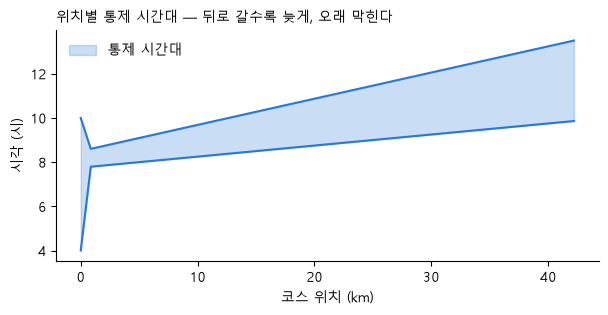

In [4]:
def window(km):
    a, b = P['T0'] + km / P['V_LEAD'] - P['PRE'], P['T0'] + km / P['V_SWEEP'] + P['POST']
    if km * 1000 < P['STAGE'][0]:                      # 집결·출발지는 새벽부터 통제
        a, b = min(a, P['STAGE'][1]), max(b, P['STAGE'][2])
    return (a, b)

def riders(seg, win):
    a, b = win
    return sum(max(0.0, min(b, h + 1) - max(a, h)) * v for stp in seg['stops'] for h, v in stp['vol'].items())

kms = np.linspace(0, 42.195, 50)
fig, ax = plt.subplots(figsize=(7, 3))
ax.fill_between(kms, [window(k)[0] for k in kms], [window(k)[1] for k in kms], color='#2a78d6', alpha=.25, label='통제 시간대')
ax.plot(kms, [window(k)[0] for k in kms], color='#2a78d6'); ax.plot(kms, [window(k)[1] for k in kms], color='#2a78d6')
ax.set_xlabel('코스 위치 (km)'); ax.set_ylabel('시각 (시)'); ax.set_title('위치별 통제 시간대 — 뒤로 갈수록 늦게, 오래 막힌다', loc='left', fontsize=10); ax.legend(frameon=False)
for s in ('top', 'right'): ax.spines[s].set_visible(False)
plt.show()

### 최적화용 배열 만들기
구간마다 양방향 **arc** 2개를 만들고, `RID[a, k]` = "arc $a$를 누적거리 $k\times10$m 지점에서 달리기 시작할 때의 피해 승객"을 미리 계산해 둔다. MILP의 위치별 비용 $c_{e,b}$는 이 표를 3km 구간대로 평균한 값이다.

In [5]:
arcs = []
for s in segs:
    arcs += [(s['id'], s['u'], s['v']), (s['id'], s['v'], s['u'])]
NA = len(arcs)
nidx = {n: i for i, n in enumerate(nodes)}; N = len(nodes)
U = np.array([nidx[a[1]] for a in arcs], dtype=np.int32); V = np.array([nidx[a[2]] for a in arcs], dtype=np.int32)
SEG = np.array([a[0] for a in arcs], dtype=np.int32)
REV = np.array([a ^ 1 for a in range(NA)], dtype=np.int32)          # 같은 구간의 반대 방향 arc
Lm = np.array([segs[a[0]]['length'] for a in arcs])
arc_of = {(a[1], a[2]): i for i, a in enumerate(arcs)}
nearest = lambda ll: min(nodes, key=lambda n: hav(nodes[n], ll))
S, F = nearest(P['START']), nearest(P['FINISH'])

STEP = P['STEP']; K = int(P['LMAX'] / STEP); ks = np.arange(K + 1) * STEP
vol = np.zeros((NA, len(HOURS)))
for a in range(NA):
    for stp in segs[SEG[a]]['stops']:
        vol[a] += [stp['vol'][h] for h in HOURS]
HA = np.array(HOURS)
def build_rid():
    """현재 일정 파라미터(P)로 피해 행렬을 만든다 — 출발 시각을 바꾸면 다시 호출"""
    R = np.zeros((NA, K + 1))
    for a in np.where(vol.sum(1) > 0)[0]:
        mid = (ks + Lm[a] / 2) / 1000
        w0 = P['T0'] + mid / P['V_LEAD'] - P['PRE']; w1 = P['T0'] + mid / P['V_SWEEP'] + P['POST']
        stage = mid * 1000 < P['STAGE'][0]
        w0 = np.where(stage, np.minimum(w0, P['STAGE'][1]), w0); w1 = np.where(stage, np.maximum(w1, P['STAGE'][2]), w1)
        R[a] = np.clip(np.minimum(w1[:, None], HA[None, :] + 1) - np.maximum(w0[:, None], HA[None, :]), 0, None) @ vol[a]
    return R
RID = build_rid()
seg_routes = [set(r for stp in segs[SEG[a]]['stops'] for r in stp['routes']) for a in range(NA)]
hw_w = np.array([1.0 if segs[SEG[a]]['hw'] in ('trunk', 'primary') else 1.6 for a in range(NA)])
print(f'arc {NA:,}개 | 출발 교차로 {nodes[S]} | 도착 교차로 {nodes[F]} | 직선거리 {hav(nodes[S], nodes[F])/1000:.1f}km')

arc 1,482개 | 출발 교차로 (37.5700896, 126.97715880000001) | 도착 교차로 (37.524592, 127.117051) | 직선거리 13.3km


## Step 4. 정체성·안전·단순성 — 제약과 벌점에 쓸 값 계산
**(1) 대회 정체성 $v_{e,k}$** — 소개서의 '정체성 점수'. arc $e$를 달리는 방향의 정면 ±30° 안, 4km 이내에 랜드마크 $k$가 있으면 "랜드마크를 보며 달리는 길이"로 센다.
JTBC는 롯데월드타워를 30km 이후 2km 이상($L_k$=2000, $[a_k,b_k]$=[30km, 결승]). 다른 대회는 `P['IDENTITY']`에 랜드마크만 바꿔 넣으면 된다.

**(2) 안전·운영** — `P['FORBID']`(건국대병원 150m 이내, 응급 동선)와 차로 수 부족 도로는 **변수에서 아예 뺀다**(제약식 9).

**(3) 코스 단순성** — 러너가 길을 외우기 쉽고, 통제 인력이 적게 드는 코스. "막히는 승객 1명 = 1점"과 같은 단위의 벌점이다.
- **방향 전환** $\tau$: 45~100° 1,000점, 100~150° 2,000점, 150° 이상 5,000점 (교차로에서 진입·진출 방위각 차이)
- **되돌아오기** $\mathcal W$: 달려온 길의 반대 차로(50m 이내, 반대 방향)로 돌아오면 겹친 길이 1m당 3점
- **같은 동네 재방문·지그재그** $\mathcal Q$: **다른** 길이라도 800m 안에서 반대 방향으로 나란히 달리면(동쪽으로 갔다가 한 블록 아래 길로 서쪽으로 돌아오는 S자·Z자), 또는 300m 안에서 같은 방향으로 나란히 달리면 겹친 길이 1m당 2점
- 그리고 제약식 (2) **같은 교차로는 한 번만** 지나므로 8자·작은 고리 코스는 처음부터 나오지 않는다.

In [6]:
def path_of(a):
    sid, u, v = arcs[a]; p = segs[sid]['path']
    return p if u == segs[sid]['u'] else p[::-1]              # 구간의 원래 노드열을 진행 방향으로

# (1) 정체성: 랜드마크 k를 정면으로 보며 달리는 길이 v[e,k]
def facing(p, q, lm):
    mid = ((p[0] + q[0]) / 2, (p[1] + q[1]) / 2)
    if hav(mid, lm['coord']) > lm['dist']:
        return False
    c = math.cos(math.radians(37.55))
    hv = ((q[1] - p[1]) * c, q[0] - p[0]); tv = ((lm['coord'][1] - mid[1]) * c, lm['coord'][0] - mid[0])
    n1, n2 = math.hypot(*hv), math.hypot(*tv)
    if n1 < 1e-12 or n2 < 1e-12:
        return False
    return math.degrees(math.acos(max(-1, min(1, (hv[0] * tv[0] + hv[1] * tv[1]) / (n1 * n2))))) <= lm['angle']

VK = np.zeros((len(P['IDENTITY']), NA))
for k, lm in enumerate(P['IDENTITY']):
    for a in range(NA):
        p = path_of(a)
        VK[k, a] = sum(hav(allnodes[x], allnodes[y]) for x, y in zip(p[:-1], p[1:]) if facing(allnodes[x], allnodes[y], lm))
view_len = VK[0]                                               # 첫 번째 랜드마크(롯데월드타워)

# (2) 금지 구간: 지정 반경 안 + 차로 수 부족
near_forbid = np.array([any(hav(allnodes[n], z['coord']) < z['r'] for z in P['FORBID'] for n in segs[SEG[a]]['path']) for a in range(NA)])
narrow = np.array([segs[SEG[a]]['lanes'] is not None and segs[SEG[a]]['lanes'] < P['MIN_LANES'] for a in range(NA)])
FORB = near_forbid | narrow

# (3) 형상: 진입·진출 방위각, 반대 차로 쌍(되돌아오기), 나란한 다른 길 쌍(재방문)
KX, KY = 88200.0, 111000.0
xy_of = lambda a: np.array([(allnodes[n][1] * KX, allnodes[n][0] * KY) for n in path_of(a)])
bearing = lambda p, q: math.degrees(math.atan2(q[0] - p[0], q[1] - p[1])) % 360
def head(pts, from_start, dist=40.0):
    seq = pts if from_start else pts[::-1]; acc, j = 0.0, 1
    while j < len(seq) - 1 and acc < dist:
        acc += np.hypot(*(seq[j] - seq[j - 1])); j += 1
    return bearing(seq[0], seq[j]) if from_start else bearing(seq[j], seq[0])
HOUT = np.zeros(NA); HIN = np.zeros(NA)       # HOUT: arc 시작부 진행 방향, HIN: arc 끝부분 진행 방향
PTS, PH, PA = [], [], []                      # 20m 간격 표본점(좌표, 방위각, 소속 arc)
for a in range(NA):
    pts = xy_of(a); HOUT[a], HIN[a] = head(pts, True), head(pts, False)
    for i in range(1, len(pts)):
        L = float(np.hypot(*(pts[i] - pts[i - 1])))
        if L < 1e-6: continue
        h = bearing(pts[i - 1], pts[i])
        for t in np.arange(0, L, 20.0):
            PTS.append(pts[i - 1] + (pts[i] - pts[i - 1]) * (t / L)); PH.append(h); PA.append(a)
PTS, PH, PA = np.array(PTS), np.array(PH), np.array(PA)
turn_angle = lambda a, b: abs((HOUT[b] - HIN[a] + 180) % 360 - 180)    # arc a 끝 → arc b 시작의 방향 전환 각도

# 되돌아오기 W: 50m 안에서 반대 방향으로 나란한 다른 구간의 arc 쌍 (겹친 길이 ≥ 120m)
cnt = {}
for i, nb in enumerate(cKDTree(PTS).query_ball_point(PTS, 50.0)):
    seen_a = set()
    for j in nb:
        b = int(PA[j])
        if SEG[b] == SEG[PA[i]] or b in seen_a: continue
        if abs((PH[i] - PH[j] + 180) % 360 - 180) > 150:
            seen_a.add(b); cnt[(int(PA[i]), b)] = cnt.get((int(PA[i]), b), 0) + 1
TWINS = {a: {int(REV[a]): float(Lm[a])} for a in range(NA)}          # 같은 구간 역주행도 되돌아오기
for (a, b), c in cnt.items():
    if c * 20.0 >= 120.0:
        TWINS[a][b] = max(TWINS[a].get(b, 0), c * 20.0); TWINS[b][a] = max(TWINS[b].get(a, 0), c * 20.0)

# 재방문 Q: 서로 다른 두 '도로 구간'이 나란히 달리는 길이 (≥ 200m)
#   반대 방향(±30°)이면 R_anti(800m) 안 = 갔다가 옆 길로 되돌아오는 지그재그
#   같은 방향이면 R_same(300m) 안, 단 같은 직선 위로 이어지는 구간(옆으로 60m 미만)은 제외
def near_pairs(R, min_overlap=200.0):
    R_same, R_anti = R
    even = PA % 2 == 0                                                 # 구간당 한 방향 arc의 표본점만
    pts, hd, sg = PTS[even], PH[even], SEG[PA[even]]
    ends = {int(s['id']): {s['u'], s['v']} for s in segs}
    out = {}
    for i, nb in enumerate(cKDTree(pts).query_ball_point(pts, R_anti)):
        si, seen = int(sg[i]), set()
        for j in nb:
            sj = int(sg[j])
            if sj <= si or sj in seen or ends[si] & ends[sj]: continue     # 같은 구간·맞닿은 구간 제외
            d = abs((hd[i] - hd[j] + 180) % 360 - 180)
            if 30 < d < 150: continue                                  # 비스듬히 만나는 길은 제외
            hx, hy = math.sin(math.radians(hd[i])), math.cos(math.radians(hd[i]))
            dx, dy = pts[j] - pts[i]
            if d <= 30 and (abs(dx * hy - dy * hx) < 60 or math.hypot(dx, dy) > R_same): continue   # 같은 방향: 옆 60m~300m만
            seen.add(sj); out[(si, sj)] = out.get((si, sj), 0) + 20.0
    return {k: v for k, v in out.items() if v >= min_overlap}
NEAR = near_pairs(P['NEAR_R'])
print(f"조망 가능 arc {int((view_len > 50).sum())}개 | 금지 arc {int(FORB.sum())}개 (병원 {int(near_forbid.sum())}, 차로 부족 {int(narrow.sum())}) | "
      f"되돌아오기 쌍 {sum(len(d) - 1 for d in TWINS.values()) // 2}쌍 | 재방문 쌍 {len(NEAR)}쌍")

조망 가능 arc 62개 | 금지 arc 12개 (병원 10, 차로 부족 2) | 되돌아오기 쌍 326쌍 | 재방문 쌍 1247쌍


## Step 5. MILP 수식과 PuLP 코드
아래 수식이 소개서 05의 "MILP로 우회 노선 + 통제 시간대 승하차 최소화, 42.195km·출발/도착·차로 수·정체성 하한을 모두 만족"을 그대로 옮긴 것이다.

### 5-1. 집합과 기호
| 기호 | 뜻 |
|---|---|
| $\mathcal{N}$ | 교차로. 출발 $s$(광화문), 도착 $f$(올림픽공원) |
| $\mathcal{E}$ | 방향이 있는 도로 구간(arc) $e=(i\to j)$, 길이 $\ell_e$. $\bar e$는 같은 도로의 반대 방향 |
| $\delta^+(i),\ \delta^-(i)$ | 교차로 $i$에서 나가는 arc, 들어오는 arc |
| $\mathcal{B}$ | 거리 구간대 $b=[\underline d_b,\ \overline d_b)$ — 0~3km, 3~6km, … (3km 단위) |
| $\mathcal{T}$ | 교차로에서 이어 달릴 수 있는 arc 쌍 $(e\to g)$ (U턴 제외) |
| $\mathcal{R},\ R_e$ | 버스 노선 전체, arc $e$ 위 정류장을 지나는 노선 |
| $\mathcal{K}$ | 대회 정체성 랜드마크 (JTBC: 롯데월드타워) |
| $\mathcal{W},\ \mathcal{Q}$ | 되돌아오기 쌍(반대 차로), 같은 동네 재방문 쌍(나란한 다른 길) |

### 5-2. 파라미터 (데이터에서 계산)
| 기호 | 뜻 | 코드 |
|---|---|---|
| $c_{e,b}$ | arc $e$를 구간대 $b$에서 달릴 때 **통제 시간대에 버스를 못 타는 승객 수**. Step 3의 $c_e(d)$를 $b$ 안에서 평균 | `band_cost()` |
| $v_{e,k}$ | arc $e$를 달리며 랜드마크 $k$를 정면으로 보는 길이(m) | `VK[k, e]` |
| $L_k,\ [a_k,b_k],\ w_k$ | 정체성 하한(m), 적용 거리 구간(m), 보상 가중치 — 소개서 JSON 스키마 | `P['IDENTITY']` |
| $\tau_{eg}$ | $e\to g$ 방향 전환 벌점 | `P['TURN']` |
| $\omega_{eg},\ \rho$ | 되돌아오기·재방문 겹침 길이(m)와 m당 벌점(3·2점) | `TWINS`, `NEAR` |
| $\alpha,\ \varepsilon,\ h_e$ | 노선 1개 가중치(60), 미세 거리비용(0.02), 도로 등급 계수(간선 1·보조간선 1.6) | `P['ALPHA']`, `P['EPS_LEN']` |
| $\underline p_e,\ \overline p_e$ | arc $e$가 시작될 수 있는 누적거리 범위: $\underline p_e = d(s,i)$, $\overline p_e = L_{max}-\ell_e-d(j,f)$ ($d$ = 최단거리) | `lo_a`, `hi_a` |

### 5-3. 결정변수
| 변수 | 종류 | 뜻 |
|---|---|---|
| $x_e$ | 0/1 | arc $e$를 코스로 쓰는가 |
| $y_{e,b}$ | 0/1 | arc $e$를 구간대 $b$에서 시작하는가 → 피해·조망을 **위치에 따라** 계산 |
| $p_e$ | 연속 | arc $e$가 시작되는 누적거리(m). 안 쓰면 0 |
| $z_{eg}$ | 연속 [0,1] | arc $e$ 다음에 $g$로 이어 달리는가 (전이 흐름) |
| $u_r$ | 연속 [0,1] | 노선 $r$이 통제 영향을 받는가 |
| $q_{eg}$ | 연속 ≥ 0 | 되돌아오기·재방문 쌍을 둘 다 쓰는가 |

### 5-4. 목적함수
$$\min\ \underbrace{\sum_{e}\sum_{b} c_{e,b}\,y_{e,b}}_{①\ \text{승객 피해}}
+\underbrace{\alpha\sum_{r\in\mathcal R} u_r}_{②\ \text{영향 노선}}
+\underbrace{\sum_{(e,g)\in\mathcal T}\tau_{eg}\,z_{eg}}_{③\ \text{방향 전환}}
+\underbrace{\sum_{(e,g)\in\mathcal W\cup\mathcal Q}\rho\,\omega_{eg}\,q_{eg}}_{④\ \text{되돌아오기·재방문}}
+\underbrace{\varepsilon\sum_e h_e\,\ell_e\,x_e}_{⑤\ \text{거리}}
-\underbrace{\sum_{k}w_k\sum_{e}\sum_{b\subseteq[a_k,b_k]}v_{e,k}\,y_{e,b}}_{⑥\ \text{정체성 보상}}$$

①②가 소개서의 "우회 노선 수 + 통제 시간대 승차 인원", ③④가 "러너가 외우기 쉬운 단순한 코스", ⑥은 정체성을 하한 이상으로 더 살리고 싶을 때 쓰는 보상($w_k=0$이면 꺼짐)이다.

### 5-5. 제약식
| 번호 | 수식 | 뜻 |
|---|---|---|
| (1) | $\displaystyle\sum_{e\in\delta^+(i)}x_e-\sum_{e\in\delta^-(i)}x_e=\begin{cases}1 & i=s\\-1 & i=f\\0 & \text{그 외}\end{cases}$ | 광화문에서 나가 올림픽공원으로 들어오는 **하나의 경로** |
| (2) | $\displaystyle\sum_{e\in\delta^-(i)}x_e\le 1$ (출발점은 0) | 같은 교차로는 **한 번만** 통과 → 8자·작은 고리 금지 |
| (3) | $\displaystyle\sum_{g}z_{ge}=x_e\ (e\notin\delta^+(s)),\quad \sum_{g}z_{eg}=x_e\ (e\notin\delta^-(f))$ | 쓰는 arc는 앞뒤 arc와 이어진다 → 방향 전환 ③을 정확히 계산 |
| (4) | $\displaystyle L_{min}\le\sum_e \ell_e x_e\le L_{max}$ | **공인 거리** 42.195km (계측 여유 405m) |
| (5) | $\displaystyle\sum_{e\in\delta^+(i)}p_e=\sum_{e\in\delta^-(i)}(p_e+\ell_e x_e)\ (i\neq s,f),\quad \sum_{e\in\delta^+(s)}p_e=0,\quad \underline p_e x_e\le p_e\le \overline p_e x_e$ | **누적거리** 전파. 코스와 떨어진 고리(subtour)를 돌면 거리가 제자리로 돌아올 수 없어 자동으로 금지된다 |
| (6) | $\displaystyle\sum_b y_{e,b}=x_e,\quad \sum_b \underline d_b\,y_{e,b}\le p_e\le\sum_b \overline d_b\,y_{e,b}$ | arc가 놓인 거리 구간대 지정 → 위치별 피해·조망 |
| (7) | $\displaystyle\sum_e\sum_{b\subseteq[a_k,b_k]}v_{e,k}\,y_{e,b}\ \ge\ L_k\quad\forall k$ | **정체성 하한**: 30km 이후 롯데타워 조망 ≥ 2km |
| (8) | $x_e+x_{\bar e}\le 1$ | 같은 도로를 두 번(왕복) 쓰지 않는다 |
| (9) | $x_e=0\quad(e\in\text{금지 구간})$ | 병원 앞·차로 부족 도로 — 변수에서 제외 |
| (10) | $u_r\ge x_e\quad\forall e,\ r\in R_e$ | 노선 $r$의 정류장이 코스 위에 하나라도 있으면 영향 노선 |
| (11) | $q_{eg}\ge X_e+X_g-1$ ($X$ = 같은 도로 양방향 $x$의 합) | 쌍을 둘 다 쓰면 벌점 |

### 5-6. 풀이 전략 — 2단계
서울 도로망 전체(arc 약 1,500개 × 구간대 15개)를 처음부터 정수로 풀면 오래 걸린다. 그래서
1. **LP 완화로 후보 회랑 추리기** — 0/1 조건을 연속(0~1)으로 풀어 같은 모델을 푼다(수 초). LP 해에서 0보다 큰 값을 받은 도로(+반대 방향)만 남긴다. 피해·노선·꺾임·정체성을 모두 반영한 **유망 도로**만 남는다. 정체성 하한을 뺀 LP도 한 번 더 풀어 그 도로까지 회랑에 넣는다(하한을 바꿔 비교하는 파레토가 같은 회랑 위에서 이뤄지도록).
2. **회랑 위 MILP** — 남은 수백 개 arc에서 0/1 조건을 살려 푼다. 솔버는 최적해와의 차이(gap)가 1% 이내임을 증명하거나 시간 제한에서 멈춘다.

> 결과는 '회랑 안에서의 최적'이다. 회랑을 넓히려면 `P['LP_EPS']`를 낮추면 된다(대신 계산 시간이 늘어난다).

In [7]:
# 5-0) 각 arc가 시작될 수 있는 누적거리 범위 [lo_a, hi_a] — 출발점·도착점까지의 최단거리로 계산 (제약식 5의 범위)
DGL = nx.DiGraph()
for a in range(NA): DGL.add_edge(int(U[a]), int(V[a]), w=float(Lm[a]))
s0, f0 = int(nidx[S]), int(nidx[F])
dS = nx.single_source_dijkstra_path_length(DGL, s0, weight='w')            # 출발 → 교차로
dF = nx.single_source_dijkstra_path_length(DGL.reverse(), f0, weight='w')  # 교차로 → 도착
lo_a = np.array([dS.get(int(U[a]), 1e9) for a in range(NA)])
hi_a = np.array([P['LMAX'] - Lm[a] - dF.get(int(V[a]), 1e9) for a in range(NA)])
OK_A = (lo_a <= hi_a) & ~FORB                                               # 42.6km 안에 넣을 수 없는 arc·금지 arc 제외

def band_cost(a, lo, hi):
    """c_{e,b}: arc a를 [lo, hi) 구간대에서 시작할 때의 평균 피해 승객 (Step 3의 RID 표에서 평균)"""
    k0, k1 = int(max(lo, lo_a[a]) // STEP), int(min(hi, hi_a[a], P['LMAX']) // STEP)
    return float(RID[a, k0:max(k1, k0) + 1].mean())

def tau(ang):
    """방향 전환 벌점 τ"""
    return 0.0 if ang < 45 else P['TURN'][0] if ang < 100 else P['TURN'][1] if ang < 150 else P['TURN'][2]

# ── PuLP 버전 호환 도우미 ──
# PuLP 4.x(2026~)는 내부가 새로 바뀌어 ① 변수를 문제 객체에서 만들고(prob.add_variable, LpVariable(...)·LpVariable.dicts 삭제)
# ② CBC를 더 이상 내장하지 않으며(PULP_CBC_CMD 삭제 → COIN_CMD, `pip install "pulp[cbc]"`) ③ solve()가 상태 정보 객체를 돌려준다.
# 아래 함수들이 3.x와 4.x 차이를 감춘다.
PULP_V4 = hasattr(pulp.LpProblem, 'add_variable') and not hasattr(pulp.LpVariable, 'dicts')

def new_var(prob, name, lb=None, ub=None, cat='Continuous'):
    """변수 하나 만들기 — 4.x는 prob.add_variable, 3.x는 LpVariable"""
    if hasattr(prob, 'add_variable'):
        return prob.add_variable(name, lowBound=lb, upBound=ub, cat=cat)
    return pulp.LpVariable(name, lowBound=lb, upBound=ub, cat=cat)

def new_vars(prob, name, keys, lb=None, ub=None, cat='Continuous'):
    """키 목록마다 변수 하나씩 (LpVariable.dicts 대신). 변수 이름은 '이름_순번'으로 단순하게."""
    return {k: new_var(prob, f'{name}_{i}', lb, ub, cat) for i, k in enumerate(keys)}

def var_value(v):
    return pulp.value(v)

def make_solver(time_limit, gap):
    """HiGHS가 있으면 HiGHS(빠름), 없으면 CBC. 둘 다 없으면 설치 방법을 알려 준다."""
    avail = pulp.listSolvers(onlyAvailable=True)
    if 'HiGHS' in avail:
        return 'HiGHS', pulp.HiGHS(msg=False, timeLimit=time_limit, gapRel=gap)
    if 'PULP_CBC_CMD' in avail:                                    # PuLP 3.x 내장 CBC
        return 'CBC', pulp.PULP_CBC_CMD(msg=False, timeLimit=time_limit, gapRel=gap, logPath='cbc.log')
    if 'COIN_CMD' in avail:                                        # PuLP 4.x + 별도 설치 CBC
        return 'CBC', pulp.COIN_CMD(msg=False, timeLimit=time_limit, gapRel=gap, logPath='cbc.log')
    raise RuntimeError(f'사용할 수 있는 솔버가 없습니다({avail}). `pip install "pulp[highs]"`(권장) 또는 `pip install "pulp[cbc]"`를 실행하세요.')

def run_solver(prob, name, solver):
    """풀고 (상태 문자열, 해 있음 여부, 최적 증명 여부, gap)을 돌려준다 — 3.x/4.x 공통"""
    res = prob.solve(solver)
    if hasattr(res, 'status_str'):                                 # PuLP 4.x: LpSolveStats
        st = str(res.status_str)
        has = bool(getattr(res, 'has_solution', st in ('Optimal', 'GapLimit', 'TimeLimit')))
        proved = st in ('Optimal', 'GapLimit')
        gap = getattr(res, 'gap_rel', None)
        return st, has, proved, gap
    st = pulp.LpStatus[prob.status]                                # PuLP 3.x: prob.status / prob.sol_status
    sol = getattr(prob, 'sol_status', 1 if prob.status == 1 else 0)
    has, proved = prob.status == 1 and sol in (1, 2), sol == 1
    gap = None
    try:
        if name == 'CBC':
            txt = open('cbc.log', encoding='utf-8', errors='ignore').read()
            ob = float(re.findall(r'Objective value:\s+([-\d.eE+]+)', txt)[-1]); lb = float(re.findall(r'Lower bound:\s+([-\d.eE+]+)', txt)[-1])
            gap = abs(ob - lb) / max(1.0, abs(ob))
        else:
            gap = float(prob.solverModel.getInfo().mip_gap)
    except Exception:
        gap = getattr(prob, 'mip_gap', None)
    return st, has, proved, gap

def model_size(prob, nvar):
    c = prob.constraints
    return nvar, len(c() if callable(c) else c)

def build_milp(A, relax=False):
    """arc 집합 A 위에 5-4·5-5의 모델을 만든다. relax=True면 0/1 조건을 푼 LP 완화."""
    A = [int(a) for a in A]; Aset = set(A); cat = 'Continuous' if relax else 'Binary'
    Nn = sorted({int(U[a]) for a in A} | {int(V[a]) for a in A})
    out_, in_ = {v: [] for v in Nn}, {v: [] for v in Nn}
    for a in A: out_[int(U[a])].append(a); in_[int(V[a])].append(a)
    prob = pulp.LpProblem('RunWay', pulp.LpMinimize)

    # ── 결정변수 ──
    x = new_vars(prob, 'x', A, 0, 1, cat)                                                   # x_e
    p = {a: new_var(prob, f'p_{i}', 0, float(hi_a[a])) for i, a in enumerate(A)}            # p_e
    B = P['BAND_KM'] * 1000; nb = int(math.ceil(P['LMAX'] / B)); Y = {}
    for a in A:                                                                            # y_{e,b}: 피해나 조망이 있는 arc만
        if vol[a].sum() == 0 and VK[:, a].max() <= 1: continue
        for b in range(nb):
            lo, hi = b * B, min((b + 1) * B, P['LMAX'])
            if hi > lo_a[a] and lo <= hi_a[a]: Y[(a, b)] = (lo, hi)                         # 갈 수 없는 구간대는 만들지 않음
    y = new_vars(prob, 'y', list(Y), 0, 1, cat)
    T = [(a, c) for v in Nn for a in in_[v] for c in out_[v] if c != REV[a]]                # 이어 달리기 쌍 (U턴 제외)
    z = new_vars(prob, 'z', T, 0, 1)                                                        # z_{eg}
    rmap = {}
    for a in A:
        for r in seg_routes[a]: rmap.setdefault(r, []).append(a)
    u = new_vars(prob, 'u', list(rmap), 0, 1)                                               # u_r
    segA = {}
    for a in A: segA.setdefault(int(SEG[a]), []).append(a)
    Xs = {s_: pulp.lpSum(x[a] for a in As) for s_, As in segA.items()}                    # 도로 구간 사용 여부 (양방향 합)
    pairs = {}
    for a in A:                                                                            # W: 되돌아오기 쌍
        for b_, l in TWINS[a].items():
            s1, s2 = sorted((int(SEG[a]), int(SEG[b_])))
            if b_ in Aset and s1 != s2:
                pairs[(s1, s2)] = (max(pairs.get((s1, s2), (0, 0))[0], l), P['PEN_TWIN'])
    for (s1, s2), l in NEAR.items():                                                       # Q: 재방문 쌍
        if s1 in segA and s2 in segA and (s1, s2) not in pairs: pairs[(s1, s2)] = (l, P['PEN_NEAR'])
    q = new_vars(prob, 'q', list(pairs), 0)

    # ── 목적함수 (5-4) ──
    prob += (pulp.lpSum(band_cost(a, *Y[(a, b)]) * y[(a, b)] for (a, b) in Y)                          # ① 승객 피해
             + P['ALPHA'] * pulp.lpSum(u.values())                                                    # ② 영향 노선
             + pulp.lpSum(tau(turn_angle(a, c)) * z[(a, c)] for (a, c) in T if turn_angle(a, c) >= 45)  # ③ 방향 전환
             + pulp.lpSum(float(pen * l) * q[k] for k, (l, pen) in pairs.items())                     # ④ 되돌아오기·재방문
             + pulp.lpSum(float(P['EPS_LEN'] * hw_w[a] * Lm[a]) * x[a] for a in A)                    # ⑤ 거리
             - pulp.lpSum(float(lm['w'] * VK[k, a]) * y[(a, b)] for k, lm in enumerate(P['IDENTITY'])  # ⑥ 정체성 보상
                          for (a, b) in Y if Y[(a, b)][0] >= lm['a'] and Y[(a, b)][1] <= lm['b']))

    # ── 제약식 (5-5) ──
    for v in Nn:
        net = 1 if v == s0 else (-1 if v == f0 else 0)
        prob += pulp.lpSum(x[a] for a in out_[v]) - pulp.lpSum(x[a] for a in in_[v]) == net          # (1) 경로
        prob += pulp.lpSum(x[a] for a in in_[v]) <= (0 if v == s0 else 1)                             # (2) 교차로 1회
        if v == s0:
            prob += pulp.lpSum(p[a] for a in out_[v]) == 0                                            # (5) 출발점 누적거리 0
        elif v != f0:
            prob += pulp.lpSum(p[a] for a in out_[v]) == pulp.lpSum(p[a] + float(Lm[a]) * x[a] for a in in_[v])  # (5) 누적거리 전파
    zin, zout = {a: [] for a in A}, {a: [] for a in A}
    for (a, c) in T: zout[a].append(z[(a, c)]); zin[c].append(z[(a, c)])
    for a in A:
        if int(U[a]) != s0: prob += pulp.lpSum(zin[a]) == x[a]                                       # (3) 앞 arc와 연결
        if int(V[a]) != f0: prob += pulp.lpSum(zout[a]) == x[a]                                      # (3) 뒤 arc와 연결
        prob += p[a] >= float(lo_a[a]) * x[a]                                                        # (5) 누적거리 범위
        prob += p[a] <= float(hi_a[a]) * x[a]
        r_ = int(REV[a])
        if r_ in Aset and a < r_: prob += x[a] + x[r_] <= 1                                            # (8) 같은 도로 한 번
    Ltot = pulp.lpSum(float(Lm[a]) * x[a] for a in A)
    prob += Ltot >= P['LMIN']; prob += Ltot <= P['LMAX']                                              # (4) 공인 거리
    byA = {}
    for k_ in Y: byA.setdefault(k_[0], []).append(k_)
    for a, ks_ in byA.items():
        prob += pulp.lpSum(y[k_] for k_ in ks_) == x[a]                                               # (6) 구간대 하나
        prob += p[a] >= pulp.lpSum(Y[k_][0] * y[k_] for k_ in ks_)                                     # (6) 구간대 하한
        prob += p[a] <= pulp.lpSum(Y[k_][1] * y[k_] for k_ in ks_)                                     # (6) 구간대 상한
    for k, lm in enumerate(P['IDENTITY']):
        prob += pulp.lpSum(float(VK[k, a]) * y[(a, b)] for (a, b) in Y
                           if Y[(a, b)][0] >= lm['a'] and Y[(a, b)][1] <= lm['b']) >= lm['L']          # (7) 정체성 하한
    for r, As in rmap.items():
        for a in As: prob += u[r] >= x[a]                                                             # (10) 영향 노선
    for (s1, s2) in pairs: prob += q[(s1, s2)] >= Xs[s1] + Xs[s2] - 1                                 # (11) 쌍 벌점
    # (9) 금지 구간은 A에 넣지 않는 것으로 처리
    nvar = len(x) + len(p) + len(y) + len(z) + len(u) + len(q)
    return prob, x, nvar

def solve_milp(A, relax=False, time_limit=None, gap=None):
    """모델을 만들고 풀어서 (LP면 x 값 dict, MILP면 arc 순서)와 풀이 정보를 돌려준다"""
    t0 = time.time()
    prob, x, nvar = build_milp(A, relax)
    name, solver = make_solver(time_limit or P['TIME_LIMIT'], gap or P['GAP'])
    st, has, proved, g = run_solver(prob, name, solver)
    nv, nc = model_size(prob, nvar)
    info = dict(solver=name, 변수=nv, 제약=nc, 상태=st, 목적함수=round(pulp.value(prob.objective) or 0) if has else None,
                초=round(time.time() - t0, 1))
    if relax:
        return {a: (var_value(x[a]) or 0.0) for a in x}, info
    info['해 종류'] = '최적해(허용 gap 이내)' if proved else ('시간 제한 — 가능해' if has else '해 없음')
    info['gap'] = g
    if not has or any(var_value(x[a]) is None for a in x):
        return None, info
    nxt = {int(U[a]): a for a in x if var_value(x[a]) > 0.5}                                            # 해에서 경로 복원
    order, v = [], s0
    while v != f0 and v in nxt and len(order) < 2000:
        order.append(nxt[v]); v = int(V[nxt[v]])
    return (order if v == f0 else None), info

print(f'PuLP {"4.x" if PULP_V4 else "3.x"} 방식 | 사용할 솔버: {make_solver(10, 0.01)[0]} | '
      f'최적화 대상 arc {int(OK_A.sum()):,}개 (전체 {NA:,}개 중 거리 범위·금지 구간 통과)')

PuLP 4.x 방식 | 사용할 솔버: HiGHS | 최적화 대상 arc 1,470개 (전체 1,482개 중 거리 범위·금지 구간 통과)


### 평가 함수 (AS-IS와 TO-BE에 똑같이 적용)
어떤 코스든 arc 순서만 주면 같은 기준으로 KPI를 계산한다. 왕복 구간처럼 **같은 구간을 두 번 지나면 통제 시간대를 합쳐서(첫 통제 시작~마지막 해제) 한 번만** 센다.

In [8]:
def evaluate(order):
    km, visits, rows, view = 0.0, {}, [], 0.0
    lm0 = P['IDENTITY'][0]
    for a in order:
        s = segs[SEG[a]]; w = window((km + s['length'] / 2) / 1000)
        v = visits.setdefault(int(SEG[a]), [w[0], w[1]]); v[0] = min(v[0], w[0]); v[1] = max(v[1], w[1])
        if lm0['a'] <= km <= lm0['b']: view += VK[0, a]               # 정체성 구간 [a_k, b_k] 안의 조망 길이
        rows.append(dict(km=round(km / 1000, 2), 도로=s['name'] or '(이름 없음)', 길이m=round(s['length']), seg=int(SEG[a])))
        km += s['length']
    tot, rset, nstop, late, kmh = 0.0, set(), 0, 0.0, 0.0
    seg_r = {}
    for sid, w in visits.items():
        s = segs[sid]; seg_r[sid] = riders(s, w); tot += seg_r[sid]; nstop += len(s['stops'])
        for stp in s['stops']: rset.update(stp['routes'])
        if w[1] > 10.0: late += s['length']
        kmh += s['length'] / 1000 * (w[1] - max(w[0], 6.0))            # 06시 이후 통제 시간만 계산
    done = set()
    for r in rows:
        w = visits[r['seg']]; r['피해'] = 0 if r['seg'] in done else round(seg_r[r['seg']]); done.add(r['seg'])
        r['통제'] = '%02d:%02d–%02d:%02d' % (int(w[0]), round(w[0] % 1 * 60) % 60, int(w[1]), round(w[1] % 1 * 60) % 60)
    turns = sum(turn_angle(a, b) >= 45 for a, b in zip(order, order[1:]))
    sharp = sum(turn_angle(a, b) >= 100 for a, b in zip(order, order[1:]))
    back, seen_a = 0.0, set()
    for b in order:
        back += max([TWINS[b].get(x, 0) for x in seen_a] + [0]); seen_a.add(b)
    return dict(length_km=round(km / 1000, 3), riders=round(tot), routes=len(rset), stops=nstop, view_m=round(view),
                late_km=round(late / 1000, 1), closure_kmh=round(kmh), junctions=len({x for a in order for x in (U[a], V[a])}), turns=int(turns), sharp=int(sharp), backtrack_km=round(back / 1000, 1),
                route_list=sorted(rset), rows=rows)

def coords(order):
    pts = []
    for a in order:
        c = [allnodes[n] for n in path_of(a)]; pts += c if not pts else c[1:]
    return pts

def road_table(ev, min_len=300):
    """연속된 같은 이름 도로를 합친 요약표"""
    seq = []
    for r in ev['rows']:
        if not seq or seq[-1]['도로'] != r['도로']:
            seq.append(dict(km=r['km'], 도로=r['도로'], 길이km=0.0, 피해=0, 통제=r['통제']))
        seq[-1]['길이km'] += r['길이m'] / 1000; seq[-1]['피해'] += r['피해']
    df = pd.DataFrame([q for q in seq if q['길이km'] * 1000 >= min_len]); df['길이km'] = df['길이km'].round(1)
    return df

BASE = [[allnodes[n] for n in w['nodes'] if n in allnodes] for w in osm['ways']]
LANDMARK = {'광화문(출발)': P['START'], '올림픽공원(도착)': P['FINISH'], **{lm['name']: lm['coord'] for lm in P['IDENTITY']}}
def draw(ax, order, color, title, corridor=None):
    for c in BASE:
        if len(c) > 1: ax.plot([p[1] for p in c], [p[0] for p in c], color='#dddcd6', lw=.5, zorder=1)
    for a in (corridor or []):                                    # 후보 회랑(있으면 연하게)
        c = [allnodes[n] for n in path_of(a)]
        ax.plot([p[1] for p in c], [p[0] for p in c], color='#9ec5f0', lw=2.2, zorder=2)
    pts = coords(order)
    ax.plot([p[1] for p in pts], [p[0] for p in pts], color='white', lw=5, zorder=3)
    ax.plot([p[1] for p in pts], [p[0] for p in pts], color=color, lw=2.8, zorder=4)
    acc, nxt = 0.0, 5000
    for p, q in zip(pts, pts[1:]):
        d = hav(p, q)
        if acc + d >= nxt:
            ax.annotate(str(nxt // 1000), (p[1], p[0]), fontsize=7, ha='center', va='center', zorder=6,
                        bbox=dict(boxstyle='circle,pad=0.15', fc='white', ec=color, lw=1)); nxt += 5000
        acc += d
    for n, (la, lo) in LANDMARK.items():
        ax.scatter([lo], [la], s=45, c='#111', marker='*' if n not in ('광화문(출발)', '올림픽공원(도착)') else 'o', zorder=7)
        ax.annotate(n, (lo, la), xytext=(5, 6), textcoords='offset points', fontsize=8, zorder=7,
                    bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=.85))
    ax.set_xlim(126.955, 127.150); ax.set_ylim(37.460, 37.600); ax.set_aspect(1 / math.cos(math.radians(37.55)))
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, loc='left', fontsize=10)
    for s in ax.spines.values(): s.set_visible(False)

## Step 6. AS-IS — 2026 JTBC 서울마라톤 풀코스
공식 풀코스 안내의 경유지 순서를 그대로 따른다.

광화문광장 → 숭례문 오거리 → 한국은행 앞 사거리 → 시청 삼거리 → 을지로1가 → 대림상가(반환) → 을지로2가 → 비우당교(반환) → 모전교 → 종로구청입구 교차로
→ 신설동 오거리 → 군자역 → 건대입구역 → 자양사거리 → 석촌호수사거리 → 학원사거리 → 학여울역(반환) → 수서IC → 둔촌사거리(반환) → 올림픽공원

경유지 사이는 도로 그래프의 **최단 경로**로 잇고, 공식 약도의 km 표지(5K, 10K, …)와 비교해 제대로 옮겨졌는지 검증한다.

{'length_km': 43.163, 'riders': 32110, 'routes': 156, 'stops': 157, 'view_m': 1168, 'late_km': 29.6, 'closure_kmh': 91, 'junctions': 57, 'turns': 21, 'sharp': 6, 'backtrack_km': 5.9}


,지점,공식_km,모델_km,차이_km
0,을지로2가,5.000,5.0,0.0
1,청계4가,7.500,6.1,-1.4
2,비우당교(반환),10.000,8.4,-1.6
3,청계4가,12.500,10.7,-1.8
4,신설동 오거리,17.500,16.3,-1.2
5,군자역,22.500,21.8,-0.7
6,건대입구역,25.000,23.8,-1.2
7,학여울역(반환),32.700,32.6,-0.1
8,수서IC,35.300,36.7,1.4
9,둔촌사거리(반환),41.000,42.4,1.4


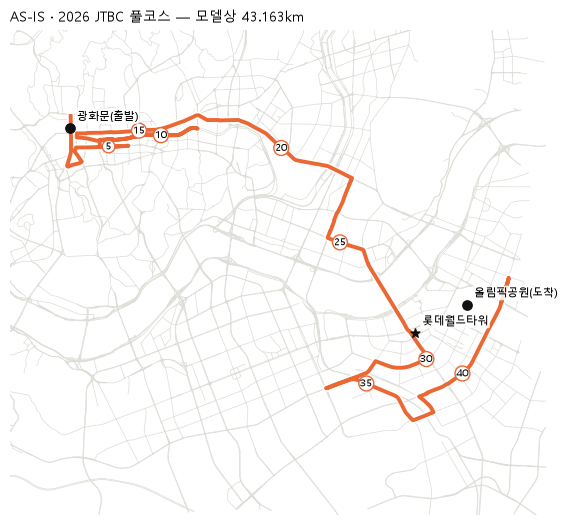

,km,도로,길이km,피해,통제
0,0.00,세종대로,1.4,3136,04:00–10:00
1,1.44,남대문로,0.5,511,07:50–08:42
2,2.33,을지로,2.7,1003,07:52–08:47
3,5.20,청계천로,7.1,148,08:01–09:51
4,12.40,종로,3.9,9317,08:23–09:59
5,16.30,천호대로,5.5,4591,08:35–10:28
6,21.77,능동로,2.0,2755,08:52–11:09
7,23.81,아차산로,1.2,795,08:58–11:23
8,24.98,자양로,3.0,1682,09:01–11:29
9,27.95,송파대로,1.1,2256,09:10–11:52


In [9]:
ASIS_WP = [   # (이름, 좌표, 공식 약도의 km 표지 — 없으면 None)
    ('광화문광장(출발)', (37.5753, 126.9771), 0.0), ('숭례문 오거리', (37.5600, 126.9755), None), ('한국은행 앞 사거리', (37.5622, 126.9805), None),
    ('시청 삼거리', (37.5655, 126.9778), None), ('을지로1가', (37.5660, 126.9822), None), ('대림상가(반환)', (37.5663, 126.9958), None),
    ('을지로2가', (37.5661, 126.9865), 5.0), ('청계2가', (37.5687, 126.9870), None), ('청계4가', (37.5687, 126.9978), 7.5),
    ('청계7가', (37.5701, 127.0150), None), ('비우당교(반환)', (37.5718, 127.0247), 10.0), ('청계7가', (37.5701, 127.0150), None),
    ('청계4가', (37.5687, 126.9978), 12.5), ('모전교', (37.5690, 126.9790), None), ('종로구청입구 교차로', (37.5703, 126.9800), None),
    ('종로5가', (37.5708, 127.0020), None), ('신설동 오거리', (37.5756, 127.0246), 17.5), ('군자역', (37.5571, 127.0794), 22.5),
    ('건대입구역', (37.5404, 127.0702), 25.0), ('잠실역', (37.5133, 127.1001), None), ('석촌호수사거리(석촌역)', (37.5054, 127.1069), None),
    ('삼전역', (37.5046, 127.0880), None), ('학여울역(반환)', (37.4967, 127.0713), 32.7), ('수서IC', (37.4896, 127.1092), 35.3), ('양재대로 진입', (37.4944, 127.1042), None),
    ('둔촌사거리(반환)', (37.5277, 127.1365), 41.0), ('올림픽공원 남2문(도착)', (37.5215, 127.1339), 42.195),
]
DG = nx.DiGraph()
for a in range(NA):
    DG.add_edge(arcs[a][1], arcs[a][2], w=Lm[a], arc=a)
asis, chk, prev = [], [], nearest(ASIS_WP[0][1])
for name, ll, official in ASIS_WP[1:]:
    n = nearest(ll)
    if n != prev:
        p = nx.shortest_path(DG, prev, n, weight='w'); asis += [DG[x][y]['arc'] for x, y in zip(p[:-1], p[1:])]
    km_now = sum(Lm[a] for a in asis) / 1000
    if official is not None:
        chk.append(dict(지점=name, 공식_km=official, 모델_km=round(km_now, 1), 차이_km=round(km_now - official, 1)))
    prev = n
ev_asis = evaluate(asis)
print({k: v for k, v in ev_asis.items() if k not in ('rows', 'route_list')})
display(pd.DataFrame(chk))
fig, ax = plt.subplots(figsize=(9, 6.3)); draw(ax, asis, '#eb6834', f"AS-IS · 2026 JTBC 풀코스 — 모델상 {ev_asis['length_km']}km"); plt.show()
display(road_table(ev_asis, 500))

**AS-IS 검증 메모**
- 공식 km 표지와의 차이는 위 표와 같다(대부분 ±2km 이내). 도로 그래프가 간선급 도로만 담고 있어(석촌호수로·삼학사로 같은 이면도로 없음) 후반부가 실제보다 조금 길게 이어지고, 모델상 총 길이가 42.195km보다 길다.
- 보도에 따르면 2026 대회 당일 **시내버스 190개 노선이 우회 운행**했다. 아래 모델의 '영향 받는 버스 노선' 수와 비교해 모델이 현실 규모를 재현하는지 볼 수 있다(모델은 코스 위에 정류장이 있는 노선만 세므로 실제보다 적게 나오는 것이 정상).
- 주최 측 GPX를 받으면 `asis`만 교체해 같은 `evaluate()`로 평가하면 된다.

## Step 7. TO-BE — PuLP로 최적 코스 계산
5-6의 2단계를 실행한다. ① 전체 도로망 LP 완화 → 후보 회랑 ② 회랑 위 MILP.
출력의 `gap`은 솔버가 증명한 "찾은 해가 최적해보다 최대 몇 % 나쁠 수 있는가"이다(0.01 = 1%).

① LP 완화: arc 1,470개, 6.1초, LP 목적함수(하한) 24,239 → 회랑 384개 arc
② MILP(HiGHS): 변수 4,440개, 제약 5,052개, 184.5초, 최적해(허용 gap 이내), 목적함수 38,336, gap -%
{'length_km': 42.256, 'riders': 10815, 'routes': 84, 'stops': 136, 'view_m': 2528, 'late_km': 29.6, 'closure_kmh': 94, 'junctions': 56, 'turns': 15, 'sharp': 1, 'backtrack_km': 0.0}


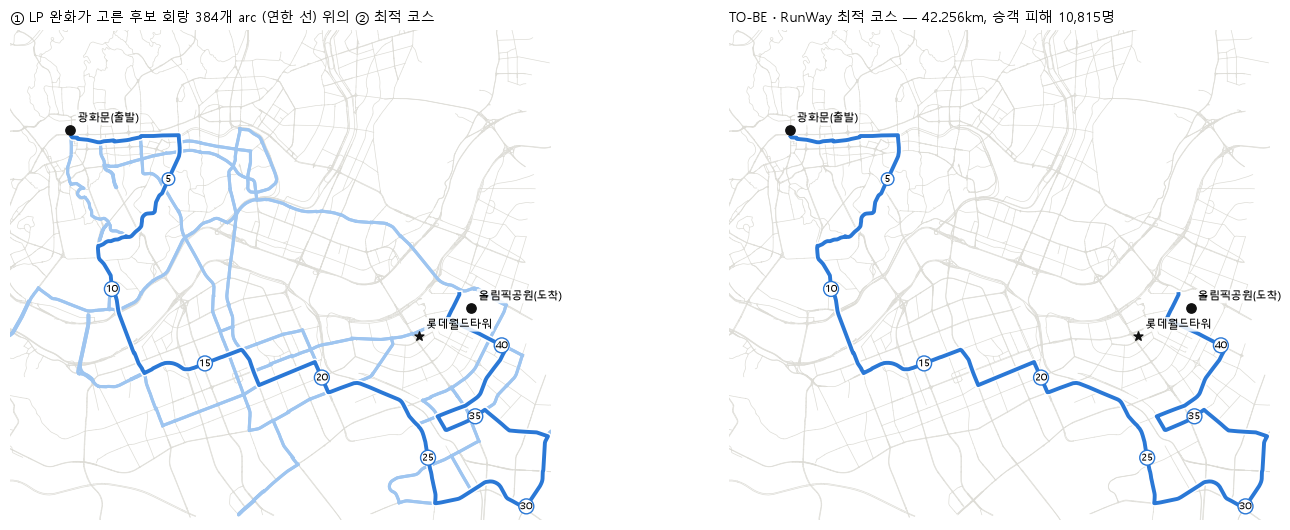

,km,도로,길이km,피해,통제
0,0.00,청계천로,3.4,35,04:00–10:00
1,3.40,다산로,3.1,1121,07:55–08:55
2,6.52,소월로,0.8,71,08:05–09:18
3,7.35,회나무로,1.0,260,08:09–09:26
4,8.32,녹사평대로,1.5,706,08:12–09:35
5,9.87,반포대로,2.8,935,08:18–09:49
6,12.69,사평대로,2.0,288,08:24–10:01
7,14.67,봉은사로,1.3,321,08:30–10:17
8,15.97,언주로,1.2,564,08:34–10:26
9,17.21,역삼로,1.9,730,08:38–10:34


In [10]:
def optimize(time_limit=None, verbose=True, extra=()):
    """LP 완화로 회랑을 고르고, 회랑 위 MILP로 최적 코스를 구한다.
    회랑 = (현재 제약의 LP 해) ∪ (정체성 하한을 뺀 LP 해) ∪ extra(이전에 찾은 코스) — 정체성 하한을 바꿔도 서로의 해를 비교할 수 있도록"""
    A_all = [a for a in range(NA) if OK_A[a]]
    xv, info_lp = solve_milp(A_all, relax=True)                                              # ① LP 완화 (현재 제약)
    keep = {a for a in A_all if xv.get(a, 0) > P['LP_EPS']}
    L_keep = [lm['L'] for lm in P['IDENTITY']]
    for lm in P['IDENTITY']: lm['L'] = 0.0
    xv0, _ = solve_milp(A_all, relax=True)                                                   # ① LP 완화 (정체성 하한 없이)
    for lm, L in zip(P['IDENTITY'], L_keep): lm['L'] = L
    keep |= {a for a in A_all if xv0.get(a, 0) > P['LP_EPS']} | {int(a) for a in extra}
    corr = sorted({b for a in keep for b in (a, int(REV[a])) if OK_A[b]})                     # 회랑 = LP가 고른 도로 + 반대 방향
    order, info = solve_milp(corr, time_limit=time_limit)                                    # ② 회랑 위 MILP
    info.update(LP하한=info_lp['목적함수'], LP초=info_lp['초'], 회랑arc=len(corr), 전체arc=len(A_all))
    if verbose:
        n = lambda v: '-' if v is None else f'{v:,}'
        print(f"① LP 완화: arc {len(A_all):,}개, {info_lp['초']}초, LP 목적함수(하한) {n(info_lp['목적함수'])} → 회랑 {len(corr)}개 arc")
        print(f"② MILP({info['solver']}): 변수 {info['변수']:,}개, 제약 {info['제약']:,}개, {info['초']}초, {info['해 종류']}, "
              f"목적함수 {n(info['목적함수'])}, gap {'-' if info['gap'] is None else round(info['gap'] * 100, 2)}%")
    return order, info, corr

tobe, info_tobe, corr_tobe = optimize()
if tobe is None:
    raise RuntimeError(f"시간 제한 안에 해를 찾지 못했습니다({info_tobe['상태']}). P['TIME_LIMIT']를 늘리거나 `pip install highspy`로 HiGHS 솔버를 쓰세요.")
ev_tobe = evaluate(tobe)
print({k: v for k, v in ev_tobe.items() if k not in ('rows', 'route_list')})
fig, axs = plt.subplots(1, 2, figsize=(15, 5.4))
draw(axs[0], tobe, '#2a78d6', f"① LP 완화가 고른 후보 회랑 {len(corr_tobe)}개 arc (연한 선) 위의 ② 최적 코스", corridor=corr_tobe)
draw(axs[1], tobe, '#2a78d6', f"TO-BE · RunWay 최적 코스 — {ev_tobe['length_km']}km, 승객 피해 {ev_tobe['riders']:,}명")
plt.tight_layout(); plt.show()
display(road_table(ev_tobe, 500))

## Step 8. 정체성 파레토 — "조망을 1km 줄이면 승객이 몇 명 줄어드나?"
소개서의 핵심 기능 3. 정체성 하한 $L_k$(롯데타워 조망)만 바꿔 가며 다시 풀어, **시민 피해와 러너 경험 사이의 교환 관계**를 보여 준다.
협의 자리에서 "어디까지 양보할지"를 숫자로 고를 수 있게 하는 표다.

목적함수는 하한 $L_k$와 무관하므로, 여러 번 풀며 찾은 코스를 모두 모아 각 하한마다 '조망 ≥ $L_k$'를 만족하는 코스 중 목적함수가 가장 작은 것을 고른다.
그래서 **최종 TO-BE = 기본 하한(2km)에서 가장 좋은 코스**로 여기서 확정하고, Step 9에서 AS-IS와 비교한다.

> 시나리오 한 번에 300초까지만 풀므로, 그 안에 해를 못 찾은 하한은 '300초 안에 해를 못 찾음'으로 표시된다. 아래 코드의 `time_limit=300`을 늘리거나 `pip install highspy`로 더 빠른 HiGHS 솔버를 쓰면 채워진다.

,조망 하한(km),실제 조망(km),승객 피해,영향 노선,방향 전환,목적함수,길이(km)
0,0.0,2.5,10815,84,15,38336,42.256
1,1.0,2.5,10815,84,15,38336,42.256
2,2.0,2.5,10815,84,15,38336,42.256
3,3.0,3.4,16906,89,12,43332,42.224


최종 TO-BE: {'length_km': 42.256, 'riders': 10815, 'routes': 84, 'stops': 136, 'view_m': 2528, 'late_km': 29.6, 'closure_kmh': 94, 'junctions': 56, 'turns': 15, 'sharp': 1, 'backtrack_km': 0.0}


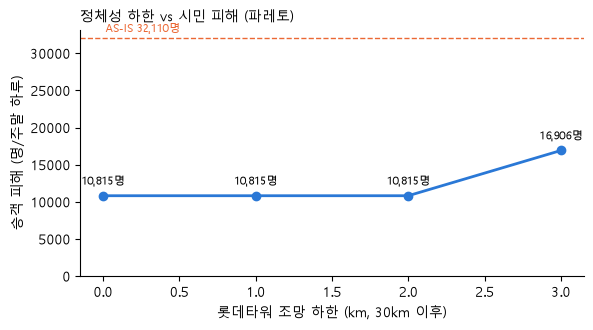

In [11]:
L_KEEP, found = P['IDENTITY'][0]['L'], [(tobe, info_tobe['목적함수'])]
for L in (0.0, 1000.0, 3000.0):                                          # 2km(기본)는 Step 7에서 이미 풀었다
    P['IDENTITY'][0]['L'] = L
    o, info, _ = optimize(time_limit=300, verbose=False, extra={a for c, _ in found for a in c})   # 앞에서 찾은 코스도 회랑에 포함
    P['IDENTITY'][0]['L'] = L_KEEP
    if o is not None: found.append((o, info['목적함수']))
# 목적함수는 하한 L과 무관하므로, 각 L마다 '조망 ≥ L'을 만족하는 해 가운데 목적함수가 가장 작은 해를 고른다
#  → 솔버가 허용 gap(1%) 안에서 멈춰 생기는 들쭉날쭉함 없이, 하한이 커질수록 피해가 줄지 않는 곡선이 된다
pareto = []
for L in (0.0, 1000.0, 2000.0, 3000.0):
    ok = [(obj, o) for o, obj in found if evaluate(o)['view_m'] >= L]
    if not ok:
        pareto.append({'조망 하한(km)': L / 1000, '상태': '300초 안에 해를 못 찾음'}); continue
    obj, o = min(ok, key=lambda t: t[0]); e = evaluate(o)
    pareto.append({'조망 하한(km)': L / 1000, '실제 조망(km)': round(e['view_m'] / 1000, 1), '승객 피해': e['riders'], '영향 노선': e['routes'],
                   '방향 전환': e['turns'], '목적함수': obj, '길이(km)': e['length_km']})
pareto = pd.DataFrame(pareto); display(pareto)
# 최종 TO-BE: 기본 하한에서 목적함수가 가장 작은 코스
tobe = min([(obj, o) for o, obj in found if evaluate(o)['view_m'] >= L_KEEP], key=lambda t: t[0])[1]
ev_tobe = evaluate(tobe)
print('최종 TO-BE:', {k: v for k, v in ev_tobe.items() if k not in ('rows', 'route_list')})
ok_p = pareto.dropna(subset=['승객 피해'])
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(ok_p['조망 하한(km)'], ok_p['승객 피해'], 'o-', color='#2a78d6', lw=2)
for _, r in ok_p.iterrows():
    ax.annotate(f"{int(r['승객 피해']):,}명", (r['조망 하한(km)'], r['승객 피해']), xytext=(0, 8), textcoords='offset points', ha='center', fontsize=8)
ax.axhline(ev_asis['riders'], color='#eb6834', ls='--', lw=1); ax.annotate(f"AS-IS {ev_asis['riders']:,}명", (0, ev_asis['riders']), xytext=(2, 4), textcoords='offset points', fontsize=8, color='#eb6834')
ax.set_ylim(0); ax.set_xlabel('롯데타워 조망 하한 (km, 30km 이후)'); ax.set_ylabel('승객 피해 (명/주말 하루)')
ax.set_title('정체성 하한 vs 시민 피해 (파레토)', loc='left', fontsize=10)
for sp in ('top', 'right'): ax.spines[sp].set_visible(False)
plt.savefig(OUT / 'pareto_identity.png', dpi=160, bbox_inches='tight'); plt.show()

## Step 9. AS-IS vs TO-BE 비교

,지표,AS-IS,TO-BE,변화
0,코스 길이 (km),43.163,42.256,-2%
1,통제 시간대 승객 피해 (명/주말 하루),32110.000,10815.000,-66%
2,영향 받는 버스 노선 (개),156.000,84.000,-46%
3,통제되는 정류장 (곳),157.000,136.000,-13%
4,도로 통제 부담 (km×시간),91.000,94.000,+3%
5,통제 필요 교차로 (곳),57.000,56.000,-2%
6,10시 이후까지 막히는 도로 (km),29.600,29.600,+0%
7,"롯데타워 조망, 30km 이후 (km)",1.200,2.500,+108%
8,방향 전환 45°↑ (회),21.000,15.000,-29%
9,급한 방향 전환 100°↑ (회),6.000,1.000,-83%


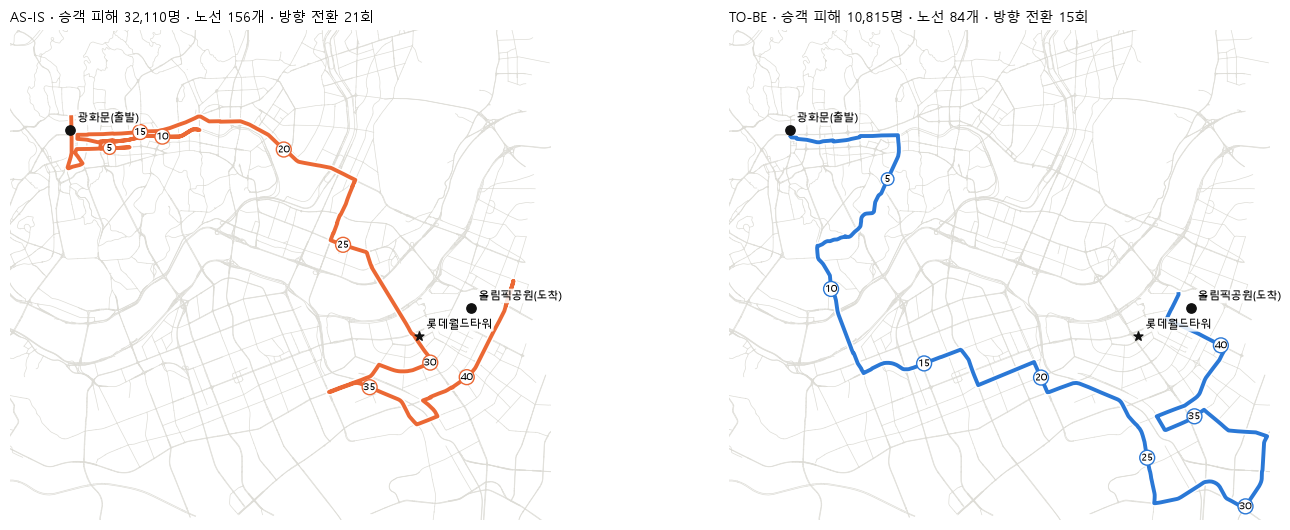

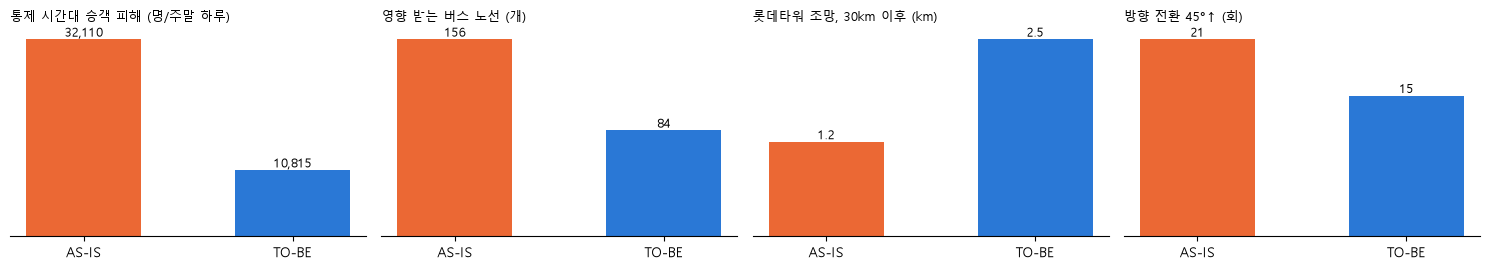

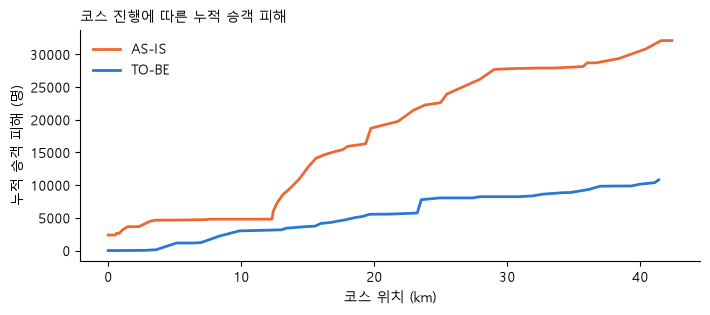

In [12]:
ROWS = [('코스 길이 (km)', 'length_km'), ('통제 시간대 승객 피해 (명/주말 하루)', 'riders'), ('영향 받는 버스 노선 (개)', 'routes'),
        ('통제되는 정류장 (곳)', 'stops'), ('도로 통제 부담 (km×시간)', 'closure_kmh'), ('통제 필요 교차로 (곳)', 'junctions'), ('10시 이후까지 막히는 도로 (km)', 'late_km'), ('롯데타워 조망, 30km 이후 (km)', 'view_m'),
        ('방향 전환 45°↑ (회)', 'turns'), ('급한 방향 전환 100°↑ (회)', 'sharp'), ('왕복 회귀 (km)', 'backtrack_km')]
val = lambda e, k: round(e[k] / 1000, 1) if k == 'view_m' else e[k]
cmp = pd.DataFrame([{'지표': n, 'AS-IS': val(ev_asis, k), 'TO-BE': val(ev_tobe, k)} for n, k in ROWS])
cmp.loc[len(cmp)] = {'지표': 'km당 승객 피해 (명/km) — 길이 차이 보정', 'AS-IS': round(ev_asis['riders'] / ev_asis['length_km']), 'TO-BE': round(ev_tobe['riders'] / ev_tobe['length_km'])}
cmp['변화'] = [f"{(t - a) / a * 100:+.0f}%" if a else '–' for a, t in zip(cmp['AS-IS'], cmp['TO-BE'])]
display(cmp)

fig, axs = plt.subplots(1, 2, figsize=(15, 5.4))
draw(axs[0], asis, '#eb6834', f"AS-IS · 승객 피해 {ev_asis['riders']:,}명 · 노선 {ev_asis['routes']}개 · 방향 전환 {ev_asis['turns']}회")
draw(axs[1], tobe, '#2a78d6', f"TO-BE · 승객 피해 {ev_tobe['riders']:,}명 · 노선 {ev_tobe['routes']}개 · 방향 전환 {ev_tobe['turns']}회")
plt.tight_layout(); plt.savefig(OUT / 'asis_tobe_map.png', dpi=160, bbox_inches='tight'); plt.show()

fig, axs = plt.subplots(1, 4, figsize=(15, 2.8))
for ax, (n, k) in zip(axs, [ROWS[1], ROWS[2], ROWS[7], ROWS[8]]):
    v = [val(ev_asis, k), val(ev_tobe, k)]
    b = ax.bar(['AS-IS', 'TO-BE'], v, color=['#eb6834', '#2a78d6'], width=.55)
    ax.bar_label(b, labels=[f'{x:,}' for x in v], fontsize=9); ax.set_title(n, fontsize=9, loc='left'); ax.set_yticks([])
    for s in ('top', 'right', 'left'): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.savefig(OUT / 'asis_tobe_kpi.png', dpi=160, bbox_inches='tight'); plt.show()

# 누적 피해가 코스 어디에서 쌓이는지
fig, ax = plt.subplots(figsize=(8, 3))
for e, c, n in ((ev_asis, '#eb6834', 'AS-IS'), (ev_tobe, '#2a78d6', 'TO-BE')):
    ax.plot([r['km'] for r in e['rows']], np.cumsum([r['피해'] for r in e['rows']]), color=c, lw=2, label=n)
ax.set_xlabel('코스 위치 (km)'); ax.set_ylabel('누적 승객 피해 (명)'); ax.legend(frameon=False)
ax.set_title('코스 진행에 따른 누적 승객 피해', loc='left', fontsize=10)
for s in ('top', 'right'): ax.spines[s].set_visible(False)
plt.show()

## Step 10. 출발 시각 시나리오 — "코스와 일정을 함께" 다시 설계
사무국 방침의 첫 번째가 **코스와 일정의 원점 재설계**다. 출발을 07:00으로 당기면 ① AS-IS 코스의 피해가 어떻게 바뀌는지, ② 그 시각에 맞춰 다시 최적화하면 코스가 어떻게 달라지는지 본다.
(07:00보다 이른 출발은 지하철 첫차로 집결하기 어려워 제외. 집결지 04~10시 통제는 그대로 둔다.)

> **해석 주의**: 수요 수준은 주말 실측이지만 **시간대 분포는 월 전체(평일 포함) 분포**라 7~9시가 실제 주말보다 크게 잡혀 있다. 그래서 출발을 당긴다고 피해가 꼭 줄지 않을 수 있다.
> 일정 결론은 주말 시간대별 원자료(교통카드 원시 데이터, 서울시·티머니 협조 필요)로 확인해야 한다. 여기서는 '출발 시각을 바꾸면 코스와 피해가 어떻게 달라지는지 계산하는 틀'을 보여 준다.

In [13]:
T0_KEEP, sched = P['T0'], []
for t0 in (7.0, 8.0):
    P['T0'] = t0; RID = build_rid()                                    # 출발 시각이 바뀌면 위치별 피해표 c_{e,b}도 바뀐다
    ea = evaluate(asis)
    o = tobe if t0 == T0_KEEP else optimize(time_limit=300, verbose=False)[0]
    cands = [c for c in (o, tobe) if c is not None]
    et = min((evaluate(c) for c in cands), key=lambda e: e['riders'])  # 회랑 밖 해가 더 나을 수도 있어 기존 TO-BE와도 비교
    sched.append({'출발': '%02d:%02d' % (int(t0), round(t0 % 1 * 60)), 'AS-IS 승객 피해': ea['riders'], 'TO-BE 승객 피해': et['riders'],
                  'TO-BE 영향 노선': et['routes'], 'TO-BE 조망(km)': round(et['view_m'] / 1000, 1), 'TO-BE 방향 전환': et['turns'],
                  '마지막 통제 해제': '%02d:%02d' % (int(t0 + 5 + P['POST']), round((t0 + 5 + P['POST']) % 1 * 60))})
P['T0'] = T0_KEEP; RID = build_rid()
sched = pd.DataFrame(sched); display(sched)

,출발,AS-IS 승객 피해,TO-BE 승객 피해,TO-BE 영향 노선,TO-BE 조망(km),TO-BE 방향 전환,마지막 통제 해제
0,07:00,33195,11951,84,2.5,15,12:30
1,08:00,32110,10815,84,2.5,15,13:30


## Step 11. 결과 저장 — 챗봇(LLM 에이전트) 연동용
소개서의 원칙 "**LLM은 경로를 그리거나 수치를 만들지 않는다. 에이전트는 도구 결과만 인용한다.**" 그대로, 에이전트는 사용자의 말을 `P`의 값으로 바꿔 `optimize()`를 부르고, 아래 파일의 숫자만 설명문에 넣는다.

| 사용자 요청 예 | 에이전트가 바꾸는 값 (제약 카드) | 호출 |
|---|---|---|
| "롯데타워 보면서 들어오는 구간은 꼭 3km 이상" | `P['IDENTITY'][0]['L'] = 3000` | `optimize()` |
| "건대병원 앞은 빼줘" | `P['FORBID'].append({...})` | Step 4 (2) 재실행 → `optimize()` |
| "출발을 7시로 당기면?" | `P['T0'] = 7.0` | `RID = build_rid()` → `optimize()` |
| "코스를 더 단순하게" | `P['TURN']` 상향 | `optimize()` |
| "이 코스는 몇 번 버스가 막혀?" | – | `evaluate(order)['route_list']` |
| 해가 없을 때(Infeasible) | 에이전트가 완화 후보 제시: 조망 하한 ↓, 금지 구간 축소, `LP_EPS` ↓ | 사용자 승인 후 재계산 |

In [14]:
def to_geojson(order, name, ev):
    return dict(type='Feature', properties=dict(name=name, **{k: v for k, v in ev.items() if k not in ('rows', 'route_list')}),
                geometry=dict(type='LineString', coordinates=[[round(lo, 6), round(la, 6)] for la, lo in coords(order)]))
json.dump(dict(type='FeatureCollection', features=[to_geojson(asis, 'AS-IS', ev_asis), to_geojson(tobe, 'TO-BE', ev_tobe)]),
          open(OUT / 'courses.geojson', 'w', encoding='utf-8'), ensure_ascii=False)
json.dump(dict(params=P, solver=info_tobe, asis=dict(order=asis, eval=ev_asis), tobe=dict(order=tobe, eval=ev_tobe)),
          open(OUT / 'result.json', 'w', encoding='utf-8'), ensure_ascii=False, default=float)
cmp.to_csv(OUT / 'kpi_compare.csv', index=False, encoding='utf-8-sig')
pareto.to_csv(OUT / 'pareto_identity.csv', index=False, encoding='utf-8-sig')
sched.to_csv(OUT / 'schedule_scenarios.csv', index=False, encoding='utf-8-sig')
print('저장:', sorted(p.name for p in OUT.iterdir()))

저장: ['asis_tobe_kpi.png', 'asis_tobe_map.png', 'courses.geojson', 'kpi_compare.csv', 'pareto_identity.csv', 'pareto_identity.png', 'result.json', 'schedule_scenarios.csv']


## 한계와 다음 단계
- **최적성의 범위**: MILP는 'LP 완화가 고른 회랑 안에서' 최적(gap 1% 이내)이다. 회랑 밖 도로까지 보장하려면 `LP_EPS`를 낮추거나 회랑을 넓혀 다시 푼다.
- **위치 근사**: 피해 비용을 3km 구간대 평균으로 근사한다(`BAND_KM`). 최종 KPI는 `evaluate()`가 10m 단위로 다시 계산한 값이다.
- **수요**: 승차량은 정류장별 **주말(토·일) 하루 평균 수준 × 월 전체 시간대 분포**로 추정했다. 주말의 실제 시간대 분포는 공개 자료에 없다.
- **노선 영향**: 코스 위 정류장만 센다. 코스를 **가로지르기만 하는 노선**의 우회, 지하철 대체 수송은 아직 없다.
- **AS-IS**: 공식 경유지를 간선 도로망 위에 옮긴 것이라 후반부가 실제보다 길다. 주최 측 GPX가 있으면 `asis`만 교체하면 된다.
- **차로 수**: OSM에 차로 수가 표시된 도로만 걸러진다(대부분 미표시 → 허용). 도로 폭 데이터(국토부 도로대장)로 보강할 수 있다.
- **조망**: 거리·방향 근사이며 건물 가림은 반영하지 않았다.
- 사무국 방침 중 소음·쓰레기 민원(주거지 노출), 기상, 인력 배치는 KPI(통제 교차로 수·통제 부담)로만 간접 반영했다.

## Step 12. 서비스 버전(v3) — 무엇이 바뀌었고, 결과는 어떻게 달라졌나
Step 0~11은 방법을 단계별로 보여 주는 **v1**이다. 해커톤 제출용 서비스(RunWay 앱·챗봇)는 같은 MILP를 `runway/` 패키지로 옮기고(노트북과 같은 숫자를 내는지 회귀 테스트로 확인), 아래를 고쳤다.

| | v1 (Step 0~11) | v3 (서비스) | 이유 |
|---|---|---|---|
| 수요 기준일 | 토·일 평균 | **일요일 4일 평균** — 원자료의 사용일자로 판별 | 대회는 일요일 오전. 토요일은 일요일보다 승차가 25~30% 많아 피해를 과대 추정 |
| 휴일 | 구분 없음 | 평일인데 승차가 적고 운행 노선이 주말 수준인 날을 **데이터 규칙으로 판별** | 10/5(개천절 대체공휴일)·10/9(한글날)이 평일 평균을 흐림 |
| 승객 목표 | 못 타는 승객 + 노선 1개당 60점 | **정류장이 코스에 들어가 버스를 못 타는 승객**만 | 승객 피해를 한 가지 정의로 명확하게 |
| 노선 지표 | 목적식에 포함 | 참고 지표 — 영향 노선 수, 우회 노선 이용객(노선×정류장 **실측**) | 노선 수는 크기를 반영하지 못함 (환승 정류장 한 곳에 노선 10~20개) |
| 결과 확정 | 솔버 1회 실행 | 찾은 해를 모두 저장하고 조건마다 서로 대입 → **같은 식으로 다시 계산한 목적함수가 더 작을 때만 교체** | 같은 조건을 다시 풀면 gap 1% 안의 다른 해가 나와 숫자가 흔들림 |
| 검증 | 공식 km 표지 대조 | + 회귀 테스트 14개 (노트북 재현, MILP 목적함수 = 재계산, 데이터 합계, 휴일 판별) | 서비스로 배포하므로 |

아래 셀은 `runway` 엔진과 미리 계산해 둔 결과(`scenarios/`)를 불러 v3 숫자를 보여 준다. (처음 실행 시 일요일 기준 도로망을 만드는 데 15~20초)

### 12-1. 사용일자로 판단한 대회일 수요
원자료 `BUS_STATION_BOARDING_MONTH_202610.csv`(노선×정류장×일별 승하차, 123만 행)를 `scripts/build_route_data.py`가 날짜 유형별로 요약한 결과다.

In [ ]:
cal = pd.read_csv(DATA / 'daytype_calendar_202610.csv', encoding='utf-8-sig')
order_ = ['weekday', 'saturday', 'sunday', 'holiday']
name_ = {'weekday': '평일', 'saturday': '토요일', 'sunday': '일요일 (대회일 유형)', 'holiday': '휴일 (데이터로 판별)'}
summ = (cal.groupby('유형').agg(일수=('date', 'size'), 하루평균_승차_만명=('승차', lambda s: round(s.mean() / 1e4)),
                               운행노선=('운행노선', 'median'), 날짜=('date', lambda s: ', '.join(d[5:] for d in s) if len(s) <= 5 else f'{len(s)}일'))
        .reindex(order_).rename(index=name_))
display(summ)
display(cal.loc[cal['유형'] == 'holiday', ['date', '요일', '승차', '운행노선', '판단근거']])

### 12-2. AS-IS vs TO-BE — v1과 v3
같은 AS-IS 코스라도 수요 기준(토·일 → 일요일)이 바뀌면 숫자가 달라진다. 비교는 **같은 기준끼리**(v1끼리, v3끼리) 해야 한다.

In [ ]:
import json as _json, sys as _sys
_sys.path.insert(0, str(Path('.').resolve()))      # runway 패키지 (이 노트북과 같은 폴더)
from runway import Engine, DEFAULT as V3
from runway.evaluate import KPI_LABELS

eng = Engine('.')
A3 = eng.asis(V3)                                   # AS-IS를 v3 기준(일요일 수요)으로 평가
T3 = eng.cached(V3)
if T3 is None:                                      # 사전 계산이 없으면 지금 푼다 (수 분)
    T3 = eng.solve(V3)
_v1 = _json.load(open(OUT / 'result.json', encoding='utf-8'))
v1_asis = globals().get('ev_asis') or _v1['asis']['eval']
v1_tobe = globals().get('ev_tobe') or _v1['tobe']['eval']

rows = []
for lab, key, lower in KPI_LABELS:
    if key in ('citizen_impact',) or key not in A3['kpi']:
        continue
    a3, t3 = A3['kpi'][key], T3['kpi'][key]
    row = {'지표': lab, 'v3 AS-IS': a3, 'v3 TO-BE': t3, 'v3 변화': f'{(t3 - a3) / a3 * 100:+.0f}%' if a3 else '–'}
    if key == 'view_km':                            # v1은 조망을 m로 저장
        a1, t1 = round(v1_asis['view_m'] / 1000, 1), round(v1_tobe['view_m'] / 1000, 1)
    elif key in v1_asis and key in v1_tobe:
        a1, t1 = v1_asis[key], v1_tobe[key]
    else:
        a1 = t1 = None
    if a1 is not None:
        row.update({'v1 AS-IS': a1, 'v1 TO-BE': t1, 'v1 변화': f'{(t1 - a1) / a1 * 100:+.0f}%' if a1 else '–'})
    rows.append(row)
cmp3 = pd.DataFrame(rows)
display(cmp3)
print('v3 TO-BE 규칙 위반:', T3['violations'] or '없음', '| AS-IS가 TO-BE 규칙을 어긴 점:', A3['violations'])
print('v3 TO-BE 풀이:', T3['solver'].get('solver'), T3['solver'].get('해 종류', ''), '| 목적함수(재계산)', T3['objective'])

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5.4))
draw(axs[0], A3['order'], '#eb6834', f"AS-IS · 못 타는 승객 {A3['kpi']['riders']:,}명 · 방향 전환 {A3['kpi']['turns']}회 (v3 기준)")
draw(axs[1], T3['order'], '#2a78d6', f"TO-BE v3 · 못 타는 승객 {T3['kpi']['riders']:,}명 · 방향 전환 {T3['kpi']['turns']}회")
plt.tight_layout(); plt.savefig(OUT / 'asis_tobe_map_v3.png', dpi=160, bbox_inches='tight'); plt.show()

from runway import evaluate as _evaluate
fig, ax = plt.subplots(figsize=(8, 3))
for res, c, n in ((A3, '#eb6834', 'AS-IS'), (T3, '#2a78d6', 'TO-BE v3')):
    r_ = _evaluate(eng.scenario(V3), res['order'])['rows']     # 구간별 피해 (같은 구간 두 번째 통과는 0)
    ax.plot([x['km'] for x in r_], np.cumsum([x['피해'] for x in r_]), color=c, lw=2, label=n)
ax.set_xlabel('코스 위치 (km)'); ax.set_ylabel('누적 못 타는 승객 (명)'); ax.legend(frameon=False)
ax.set_title('코스 진행에 따른 누적 못 타는 승객 (일요일 기준)', loc='left', fontsize=10)
for s in ('top', 'right'): ax.spines[s].set_visible(False)
plt.show()

### 12-3. 미리 계산한 시나리오 — 앱·챗봇이 즉시 답하는 결과
정체성 하한(롯데타워 조망), 출발 시각, 코스 단순성, 우회 노선 영향 반영(참고) 등 조건별 최적 코스. 앱의 사이드바 버튼과 챗봇 답변이 이 표의 숫자를 그대로 인용한다.

In [ ]:
lib = pd.DataFrame([{'조건': x['조건'], '못 타는 승객': x['kpi']['riders'], 'AS-IS 대비': f"{(x['kpi']['riders'] - A3['kpi']['riders']) / A3['kpi']['riders'] * 100:+.0f}%",
                     '영향 노선(참고)': x['kpi']['routes'], '우회 노선 이용객(참고)': x['kpi']['detour_riders'],
                     '조망 km': x['kpi']['view_km'], '방향 전환': x['kpi']['turns'], '길이 km': x['kpi']['length_km'], '목적함수': x['목적함수']}
                    for x in eng.library()]).sort_values('못 타는 승객')
display(lib)
lib.to_csv(OUT / 'scenarios_v3.csv', index=False, encoding='utf-8-sig')

### 12-4. 읽는 법과 남은 한계
- **승객 목표는 '정류장이 코스에 들어가 버스를 못 타는 승객' 하나**다. 영향 노선 수·우회 노선 이용객은 참고로만 보여 준다. 그래서 TO-BE가 못 타는 승객은 크게 줄여도 노선 수는 덜 줄 수 있다 — 도심 환승 정류장은 짧게 막혀도 노선이 많이 걸리기 때문이다. 우회 영향까지 줄이고 싶으면 `DETOUR_W`(δ)를 올린다(위 표의 '참고: 우회 노선 영향 반영').
- **시간대 분포**: 일요일의 시간대별 원자료가 없어 정류장별 월 전체 시간대 비중을 쓴다.
- **최적성**: 'LP 완화가 고른 후보 회랑 안에서 허용 gap 이내'. 그래서 찾은 해를 모두 모아 조건마다 서로 대입하고, 목적함수가 더 작을 때만 교체한다 — 다시 풀어도 발표 숫자가 나빠지지 않는다.
- **AS-IS**: 공식 경유지를 간선 도로망 위에 옮긴 코스라 모델상 길이가 실제보다 길다. 주최 측 GPX가 있으면 교체한다.

**서비스**: 같은 엔진을 Streamlit 앱(지도·KPI·조건 카드)과 Claude 챗봇으로 감쌌다. 챗봇은 사용자의 말을 제약 카드 값으로 옮겨 이 엔진을 부르고, 도구 결과의 숫자만 인용한다(답변 속 숫자를 도구 결과와 자동 대조).